In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL, DecomposeResult
from statsmodels.tsa.stattools import acf, adfuller, kpss

sys.path.insert(0, str(Path.cwd().parent))

from data_utils.fancy_barplot import fancy_bars
from data_utils.triple_plot import normality_report

In [2]:
datos_por_hoja = pd.read_excel("../data/Base_de_Datos.xlsx", sheet_name=None)
df_orec = datos_por_hoja["OREC"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_orec.columns = df_orec.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_orec = df_orec.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_orec = df_orec.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_orec.columns.name = None

In [3]:
df_orec.head()

,Año,Mes,Dia,Turno,Proceso,Indice,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2019,Oct,NaN,NaN,Rejillas,0.146401,577644,84567.536114,NaN,0,NaN,NaN,0
1,2019,Oct,NaN,NaN,Cinta,0.107361,577644,62016.19315,NaN,0,NaN,NaN,0
2,2019,Oct,NaN,NaN,Planta Oxido,0.370882,577644,214237.758155,NaN,0,NaN,NaN,0
3,2019,Oct,NaN,NaN,Empaste Casting,0.097601,577644,56378.357409,NaN,0,NaN,NaN,0
4,2019,Oct,NaN,NaN,Empaste Expanded,0.117121,577644,67654.028891,NaN,0,NaN,NaN,0


# Analizar Nulos

In [4]:
def nan_diagnosis(df: pd.DataFrame, name: str = "el df") -> None:
    """Return a graph that show null values."""
    n_cols = len(df.columns)
    ancho = max(10, int(n_cols * 0.35))
    alto = 5

    tamano_letra = max(6, 10 - n_cols // 10)

    # Porcentaje de nulos por columna
    pct_nulos = df.isnull().mean() * 100

    try:
        ax = msno.matrix(df, figsize=(ancho, alto), fontsize=tamano_letra) or plt.gca()
        plt.title(f"Patrón de Faltantes en {name}")

        if len(ax.get_xticks()) == n_cols:
            ax.set_xticks(range(n_cols))
            ax.set_xticklabels(
                [f"{c} ({p:.1f}%)" for c, p in zip(df.columns, pct_nulos, strict=False)],
                rotation=45,
                ha="left",
                fontsize=tamano_letra,
            )

        plt.show()

    except Exception:
        plt.figure(figsize=(ancho, alto))
        missing_pattern = df.isnull()

        plt.imshow(missing_pattern.astype(int), aspect="auto", cmap="RdYlGn_r")

        plt.xticks(
            ticks=range(n_cols),
            labels=[
                f"{c} ({p:.1f}%)" for c, p in zip(missing_pattern.columns, pct_nulos, strict=False)
            ],
            rotation=90,
            fontsize=tamano_letra,
            ha="center",
        )
        plt.yticks([])
        plt.title("Patrón de Faltantes (blanco = faltante)")
        plt.colorbar(label="1=Faltante, 0=Presente")

        plt.tight_layout()  # Evita que las etiquetas se corten abajo
        plt.show()

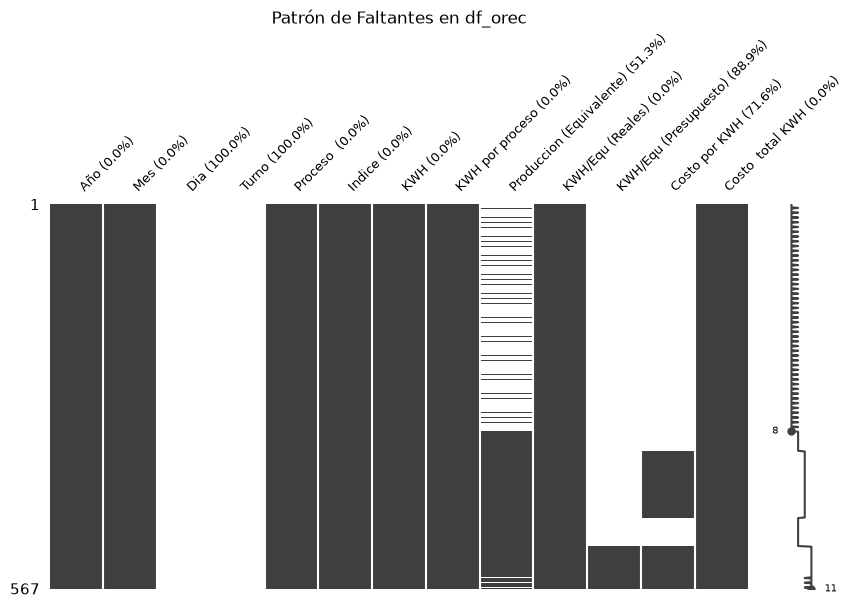

In [5]:
nan_diagnosis(df_orec, name="df_orec")

In [6]:
no_orec = df_orec[df_orec["Proceso "] != "OREC"]["Produccion (Equivalente)"]
solo_orec = df_orec[df_orec["Proceso "] == "OREC"]["Produccion (Equivalente)"]

print(f"Null values in non-OREC rows: {no_orec.isnull().sum()}")
print(f"Null values in OREC rows: {solo_orec.isnull().sum()}")

Null values in non-OREC rows: 291
Null values in OREC rows: 0


In [7]:
df_orec[df_orec["Proceso "] != "OREC"]["Produccion (Equivalente)"] * df_orec[
    df_orec["Proceso "] != "OREC"
]["Indice"]

0              NaN
1              NaN
2              NaN
3              NaN
4              NaN
          ...     
561    1029.919106
562    6346.085549
563    2036.088271
564            NaN
565    2868.960873
Length: 486, dtype: object

Al parecer 'Produccion (Equivalente) en un punto no se separaba por subprocesos.

In [8]:
df_orec.drop(columns=["Dia", "Turno"], inplace=True)

# Transformar al tipo correcto

In [9]:
df_orec = df_orec.rename(columns={"Costo  total KWH": "Costo total KWH"})

In [10]:
df_orec.info()

<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Año                       567 non-null    object
 1   Mes                       567 non-null    str   
 2   Proceso                   567 non-null    str   
 3   Indice                    567 non-null    object
 4   KWH                       567 non-null    object
 5   KWH por proceso           567 non-null    object
 6   Produccion (Equivalente)  276 non-null    object
 7   KWH/Equ (Reales)          567 non-null    object
 8   KWH/Equ (Presupuesto)     63 non-null     object
 9   Costo por KWH             161 non-null    object
 10  Costo total KWH           567 non-null    object
dtypes: object(9), str(2)
memory usage: 56.4+ KB


In [11]:
cols_numericas = [
    "Año",
    "Indice",
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

for col in cols_numericas:
    df_orec[col] = (
        df_orec[col]
        .astype(str)
        .str.strip()
        # Nota: en esta base el punto es el separador DECIMAL (0 valores con
        # coma, 567 con punto), por eso NO se eliminan los puntos.
        .str.replace(",", ".", regex=False)  # Convierte coma decimal a punto
    )

# 2. Conversión a tipos de datos específicos

# Año e Indice a enteros (usando Int64 para soportar posibles valores nulos)
df_orec["Año"] = pd.to_numeric(df_orec["Año"], errors="coerce").astype("Int64")
df_orec["Indice"] = pd.to_numeric(df_orec["Indice"], errors="coerce")
# Columnas continuas/métricas a flotantes (float64)
cols_float = [
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

for col in cols_float:
    df_orec[col] = pd.to_numeric(df_orec[col], errors="coerce")

# Columnas de texto/categoría
df_orec["Mes"] = df_orec["Mes"].astype("category")  # o .astype(str)

# Verifica el resultado
df_orec.info()

<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Año                       567 non-null    Int64   
 1   Mes                       567 non-null    category
 2   Proceso                   567 non-null    str     
 3   Indice                    567 non-null    float64 
 4   KWH                       567 non-null    float64 
 5   KWH por proceso           567 non-null    float64 
 6   Produccion (Equivalente)  276 non-null    float64 
 7   KWH/Equ (Reales)          567 non-null    float64 
 8   KWH/Equ (Presupuesto)     63 non-null     float64 
 9   Costo por KWH             161 non-null    float64 
 10  Costo total KWH           567 non-null    float64 
dtypes: Int64(1), category(1), float64(8), str(1)
memory usage: 51.6 KB


In [12]:
meses_abr = {
    "ene": 1,
    "feb": 2,
    "mar": 3,
    "abr": 4,
    "may": 5,
    "jun": 6,
    "jul": 7,
    "ago": 8,
    "sep": 9,
    "oct": 10,
    "nov": 11,
    "dic": 12,
}

# 1. Limpiar texto y mapear a número
mes_num = (
    df_orec["Mes"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(".", "", regex=False)  # Quita puntos si vienen como 'Ene.'
    .map(meses_abr)
)

# 2. Crear la columna de Fecha (primer día de cada mes)
df_orec["Fecha"] = pd.to_datetime(
    {"year": df_orec["Año"], "month": mes_num, "day": 1}, errors="coerce"
)

In [13]:
# La hoja viene en orden cronologico, 7 filas por mes (una por proceso). La fila de planta
# (OREC) de cada diciembre trae el anio siguiente: la de diciembre de 2019 dice 2020, y asi
# hasta la de diciembre de 2025, que dice 2026. Sin corregirlo la serie de planta tiene cada
# diciembre un anio tarde, le falta 2019-12 y pierde diciembre de 2025.
# Se corrige aqui, antes de repartir los dias, con el mes que le toca por posicion.
FILAS_POR_MES = 7
DICIEMBRE = 12
bloque = df_orec.index // FILAS_POR_MES
calendario = pd.date_range(df_orec["Fecha"].iloc[0], periods=bloque.max() + 1, freq="MS")
esperada = pd.Series(calendario[bloque], index=df_orec.index)

mal = df_orec["Fecha"] != esperada
desfase = (df_orec.loc[mal, "Fecha"] - esperada[mal]).dt.days

# Si la hoja cambia y el patron deja de ser este, mejor fallar que re-fechar a ciegas
procesos_por_bloque = df_orec.groupby(bloque)["Proceso "].nunique()
assert (procesos_por_bloque == FILAS_POR_MES).all(), "un bloque no trae sus 7 procesos"
assert (df_orec.loc[mal, "Proceso "].str.strip() == "OREC").all(), "solo se esperaban filas OREC"
assert (esperada[mal].dt.month == DICIEMBRE).all(), "solo se esperaban diciembres"
assert mal.sum() == (calendario.month == DICIEMBRE).sum(), "no estan todos los diciembres"
assert desfase.between(365, 366).all(), "el desfase no es de un anio exacto"

print(f"filas corregidas: {list(df_orec.index[mal])}")
print(
    f"rotulo {df_orec.loc[mal, 'Fecha'].min():%Y-%m} .. {df_orec.loc[mal, 'Fecha'].max():%Y-%m}"
    f"  ->  {esperada[mal].min():%Y-%m} .. {esperada[mal].max():%Y-%m}"
)
df_orec.loc[mal, "Año"] = esperada[mal].dt.year
df_orec.loc[mal, "Fecha"] = esperada[mal]

filas corregidas: [20, 104, 188, 272, 356, 440, 524]
rotulo 2020-12 .. 2026-12  ->  2019-12 .. 2025-12


In [14]:
base_fecha = pd.to_datetime(df_orec["Fecha"])

# 2. Número de aparición (0, 1, 2, ...) dentro de cada grupo Año-Mes
k = df_orec.groupby(["Año", "Mes"]).cumcount()

# 3. Total de registros por cada grupo Año-Mes
n = df_orec.groupby(["Año", "Mes"])["Fecha"].transform("count")

# 4. Total de días del mes específico (considera años bisiestos automáticamente)
dias_en_mes = base_fecha.dt.days_in_month

# 5. Calcular el día correspondiente con distribución uniforme entre el día 1 y el último día del
# mes
# Para n == 1 el incremento es 0 (queda día 1). Para n > 1 el último registro queda cerca del final
# del mes.
incremento_dias = (k * (dias_en_mes - 1) / (n - 1).replace(0, 1)).round()

# 6. Sumar los días a la fecha base (día 1)
df_orec["Fecha"] = base_fecha + pd.to_timedelta(incremento_dias, unit="D")

In [15]:
df_orec["Fecha"]

0     2019-10-01
1     2019-10-06
2     2019-10-11
3     2019-10-16
4     2019-10-21
         ...    
562   2026-06-11
563   2026-06-15
564   2026-06-20
565   2026-06-25
566   2026-06-30
Name: Fecha, Length: 567, dtype: datetime64[us]

# Split the data

In [16]:
df_orec.info()

<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Año                       567 non-null    Int64         
 1   Mes                       567 non-null    category      
 2   Proceso                   567 non-null    str           
 3   Indice                    567 non-null    float64       
 4   KWH                       567 non-null    float64       
 5   KWH por proceso           567 non-null    float64       
 6   Produccion (Equivalente)  276 non-null    float64       
 7   KWH/Equ (Reales)          567 non-null    float64       
 8   KWH/Equ (Presupuesto)     63 non-null     float64       
 9   Costo por KWH             161 non-null    float64       
 10  Costo total KWH           567 non-null    float64       
 11  Fecha                     567 non-null    datetime64[us]
dtypes: Int64(1), category(1), datetim

In [17]:
# El split tiene que ser temporal, asi que las filas se ordenan por fecha antes
# de partirlas. df_orec no se toca: las secciones de series de tiempo dependen
# de el. El indice original se conserva, para poder rastrear cada fila.
orden = df_orec.sort_values("Fecha")

X = orden.drop(columns=["Mes", "Año", "Produccion (Equivalente)"])
y = orden["Produccion (Equivalente)"]
X.shape, y.shape

((567, 9), (567,))

In [18]:
# Split temporal: el ultimo fold de TimeSeriesSplit deja todo el pasado en train y el
# futuro en test.
CORTE = "2025-01-01"
test_size = int((X["Fecha"] >= CORTE).sum())  # alineado a inicio de mes

# n_splits=2 es el minimo que admite sklearn; solo interesa el ultimo fold, el que
# entrena con todo lo anterior al corte. El corte se expresa en fechas y no en un
# numero de filas para que la frontera caiga siempre en un inicio de mes.
tscv = TimeSeriesSplit(n_splits=2, test_size=test_size)
*_, (i_train, i_test) = tscv.split(X)

X_train, X_test = X.iloc[i_train], X.iloc[i_test]
y_train, y_test = y.iloc[i_train], y.iloc[i_test]

In [19]:
print(
    f"train {X_train['Fecha'].min():%Y-%m} -> {X_train['Fecha'].max():%Y-%m}"
    f"  ({len(X_train)} filas)"
)
print(
    f"test  {X_test['Fecha'].min():%Y-%m} -> {X_test['Fecha'].max():%Y-%m}  ({len(X_test)} filas)"
)
print(
    f"sin solape: {X_train['Fecha'].max() < X_test['Fecha'].min()}  |  "
    f"target no nulo: train={y_train.notna().sum()} test={y_test.notna().sum()}"
)
X_train.shape, X_test.shape

train 2019-10 -> 2024-12  (441 filas)
test  2025-01 -> 2026-06  (126 filas)
sin solape: True  |  target no nulo: train=153 test=123


((441, 9), (126, 9))

In [20]:
df_train = pd.concat([X_train, y_train], axis=1)

# Iniciar el análisis exploratorio de datos (EDA) con las funciones personalizadas

In [21]:
df_train.columns

Index(['Proceso ', 'Indice', 'KWH', 'KWH por proceso', 'KWH/Equ (Reales)',
       'KWH/Equ (Presupuesto)', 'Costo por KWH', 'Costo total KWH', 'Fecha',
       'Produccion (Equivalente)'],
      dtype='str')

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 7 distinct values across 441 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)
findfont: Failed to find font weight medium for Arial, now using 400.


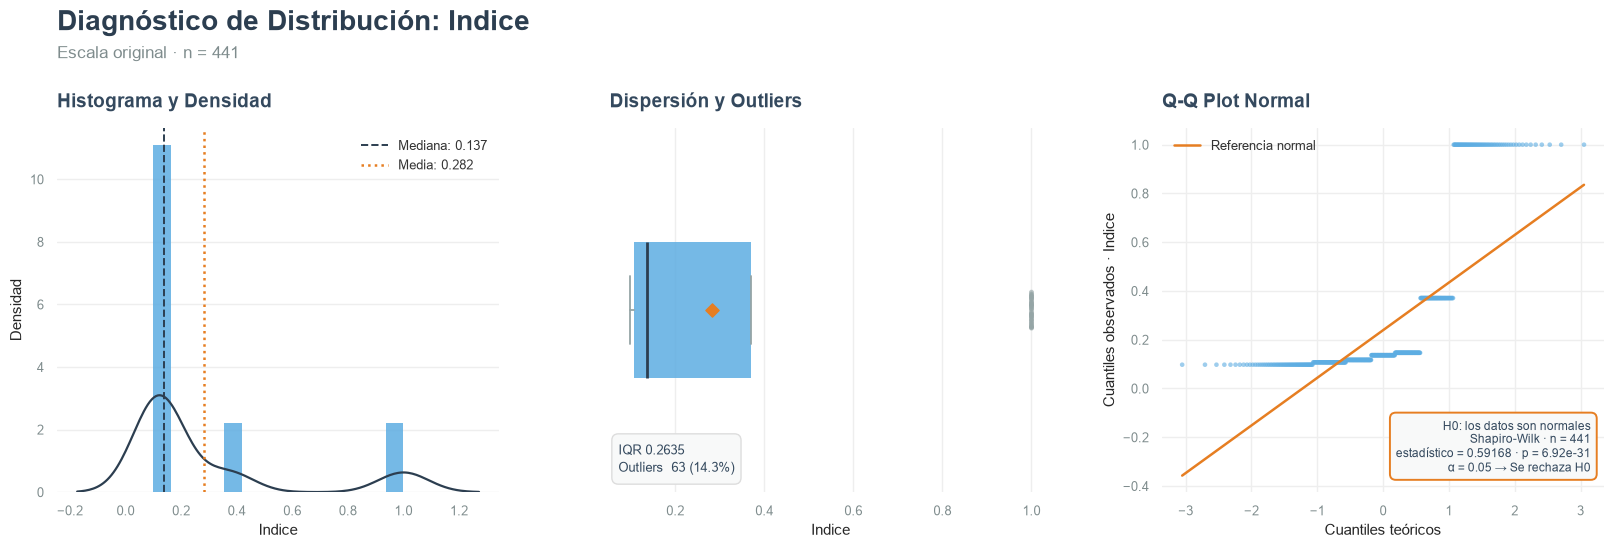

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 63 distinct values across 441 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


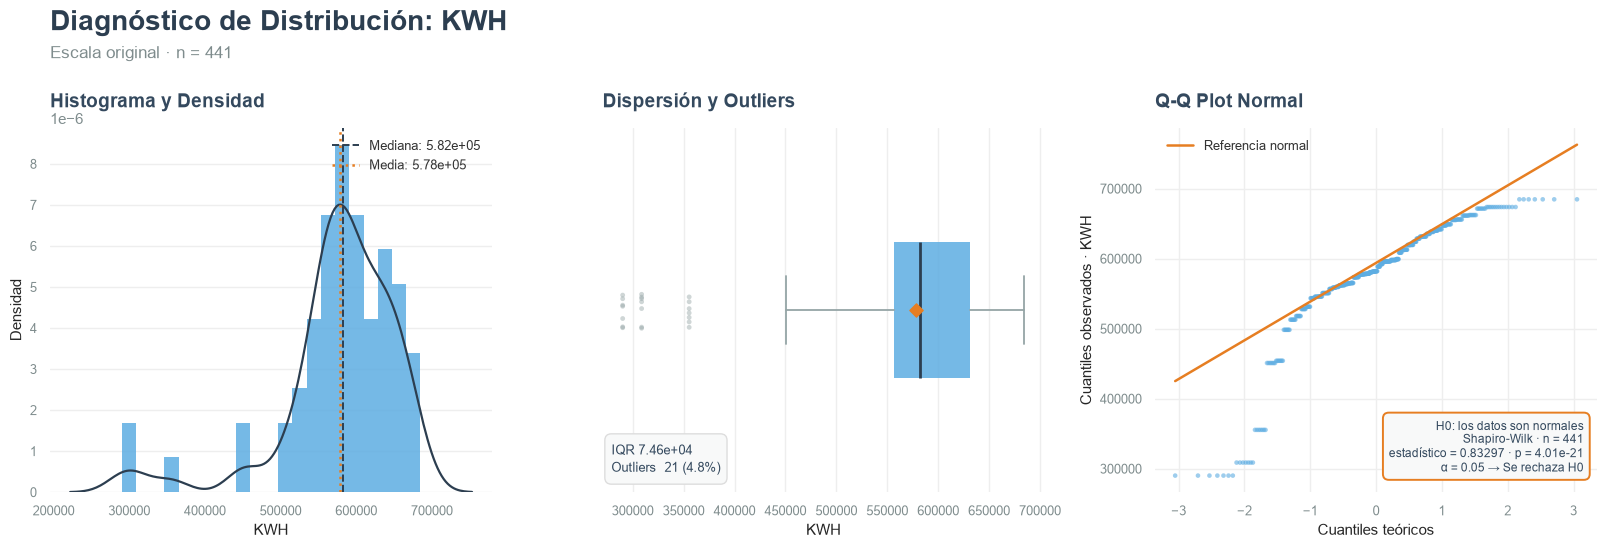

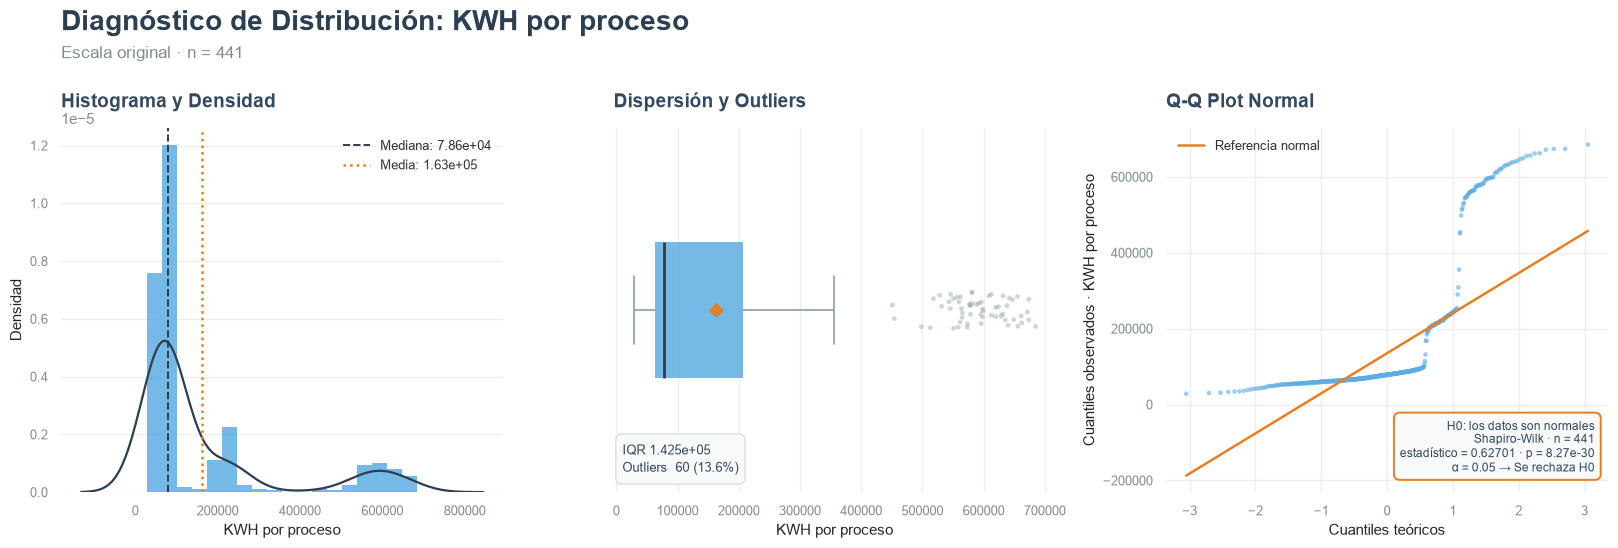

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 154 distinct values across 441 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


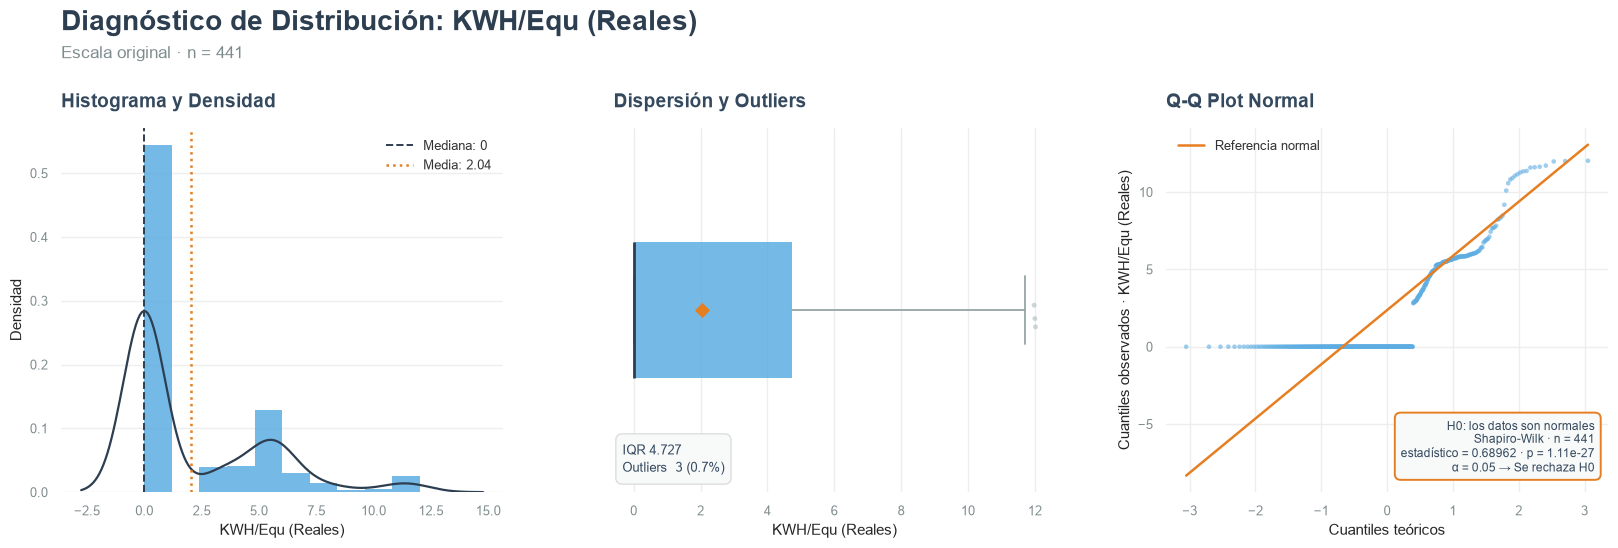

KWH/Equ (Presupuesto): 0 valores validos en train, se omite (se registra desde una fecha posterior al corte)


d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 11 distinct values across 77 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


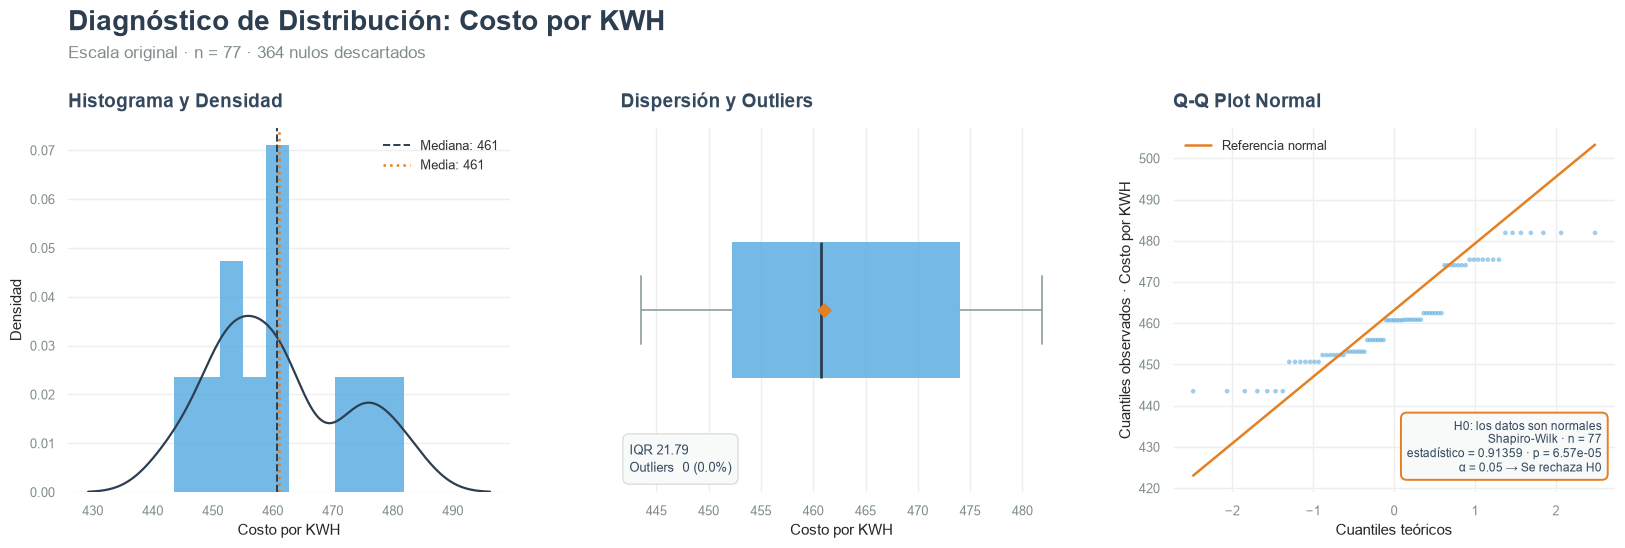

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 78 distinct values across 441 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


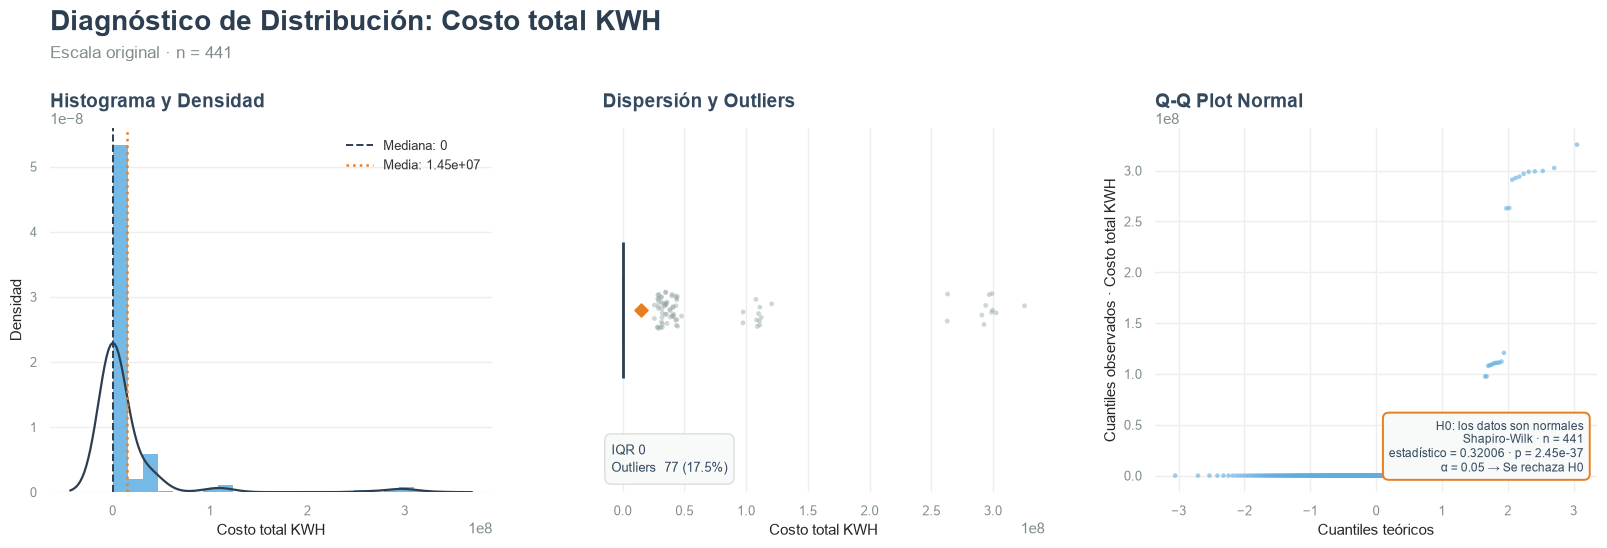

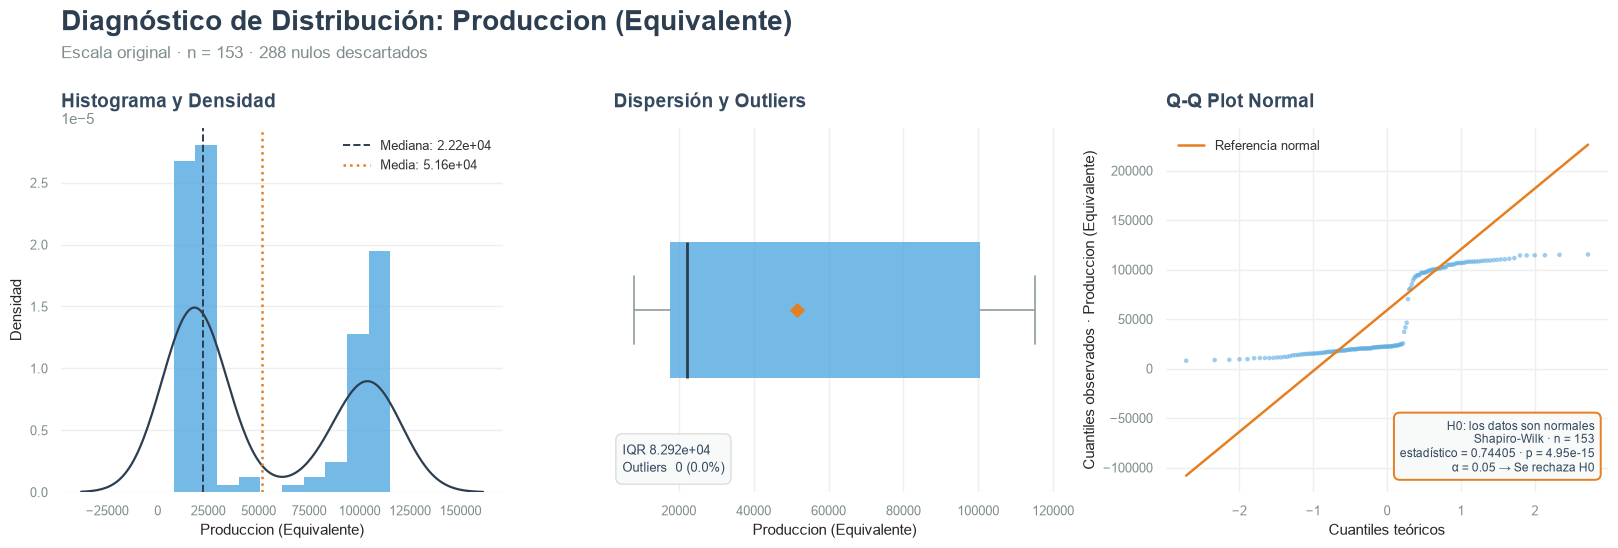

In [22]:
# El split es temporal, asi que una columna que empieza a registrarse tarde puede
# quedar vacia en train: KWH/Equ (Presupuesto) arranca en 2025-10, ya dentro de la
# ventana de test. normality_report exige un minimo de 8 valores, asi que se avisa
# y se sigue en vez de cortar el notebook.
MIN_VALIDOS = 8

for col in df_train.columns:
    if df_train[col].dtype == "int64" or df_train[col].dtype == "float64":
        validos = df_train[col].dropna().size
        if validos < MIN_VALIDOS:
            print(
                f"{col}: {validos} valores validos en train, se omite "
                f"(se registra desde una fecha posterior al corte)"
            )
            continue
        normality_report(df_train, col)

La fabrica tiene 2 picos en sus valores de produccion, sin embargo es valioso filtrar solo por orec para no caer en conclusiones desasertadas que estan separadas por proceso.

<Axes: title={'left': 'Distribución de Proceso '}, xlabel='Proceso ', ylabel='Conteo'>

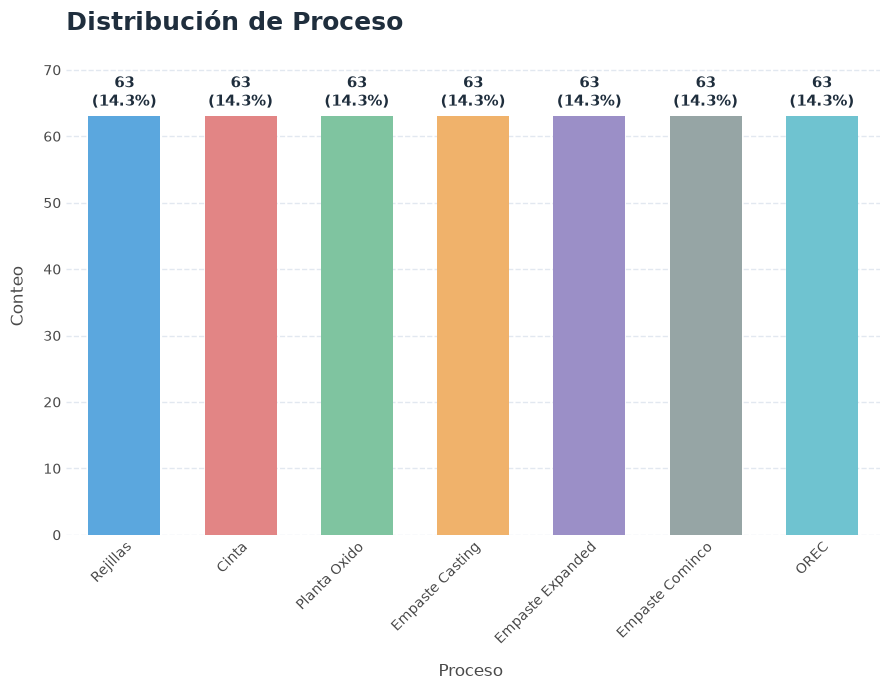

In [23]:
fancy_bars(df_train, "Proceso ", labels="both", rot=45)

## Ahondando en los atipicos

In [24]:
cols = ["Costo total KWH", "Costo por KWH", "KWH/Equ (Reales)", "KWH por proceso"]

# Los ceros y nulos son estructurales (proceso sin registro), no mediciones:
# incluirlos deformaria el IQR. Todo se calcula sobre valores > 0.
resumen = []
for col in cols:
    s = df_orec[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    resumen.append(
        {
            "columna": col,
            "n": len(s),
            "atipicos": len(atipicos),
            "mediana": s.median(),
            "maximo": s.max(),
            "max/mediana": s.max() / s.median(),
        }
    )

pd.DataFrame(resumen).round(1)

,columna,n,atipicos,mediana,maximo,max/mediana
0,Costo total KWH,157,20,38632830.9,354132062.7,9.2
1,Costo por KWH,161,0,513.1,568.5,1.1
2,KWH/Equ (Reales),275,38,5.6,944.1,168.6
3,KWH por proceso,563,75,77466.9,684713.0,8.8


In [25]:
# Algunos valores atipicos concretos (los 5 mas altos de cada columna)
for col in cols:
    s = df_orec[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    print(f"{col} -> {len(atipicos)} atipicos")
    print(atipicos.nlargest(5).to_string())

Costo total KWH -> 20 atipicos
461    3.541321e+08
447    3.298550e+08
405    3.255245e+08
510    3.190903e+08
454    3.087664e+08
Costo por KWH -> 0 atipicos
Series([], )
KWH/Equ (Reales) -> 38 atipicos
522    944.051319
536     20.808488
541     15.556898
562     14.742852
513     14.646067
KWH por proceso -> 75 atipicos
405    684713.0
419    673740.0
223    673694.0
412    671460.0
356    662248.0


Costo total KWH        mediana=  38,632,830.9  max= 354,132,062.7  ordenes=0.96
Costo por KWH          mediana=         513.1  max=         568.5  ordenes=0.04
KWH/Equ (Reales)       mediana=           5.6  max=         944.1  ordenes=2.23
KWH por proceso        mediana=      77,466.9  max=     684,713.0  ordenes=0.95


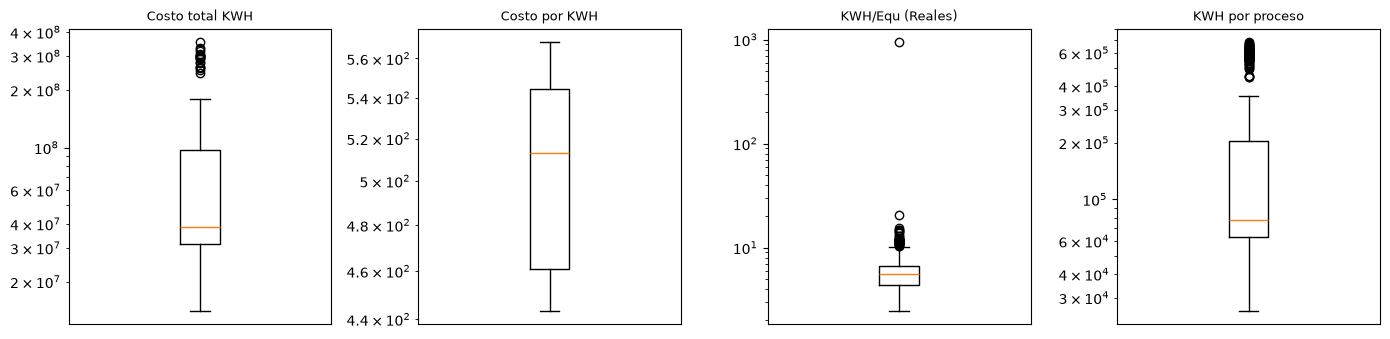

In [26]:
# Ordenes de magnitud entre el maximo y la mediana
for col in cols:
    s = df_orec.loc[df_orec[col] > 0, col].dropna()
    print(
        f"{col:<22} mediana={s.median():>14,.1f}  max={s.max():>14,.1f}  "
        f"ordenes={np.log10(s.max() / s.median()):.2f}"
    )

# Escala log: si la caja se ve aplastada contra el eje, la cola abarca ordenes de magnitud
fig, axes = plt.subplots(1, len(cols), figsize=(14, 3.5))
for ax, col in zip(axes, cols, strict=False):
    ax.boxplot(df_orec.loc[df_orec[col] > 0, col].dropna())
    ax.set_yscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [27]:
# Metricas explicitas del resumen de abajo
filas = []
for col in cols:
    s = df_orec[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    filas.append(
        {
            "columna": col,
            "n": len(s),
            "atipicos": len(atipicos),
            "mediana": s.median(),
            "maximo": s.max(),
            "max_sobre_mediana": s.max() / s.median(),
            "ordenes": np.log10(s.max() / s.median()),
            # Ceros y nulos contados sobre df_orec completo (567 filas)
            "ceros_df_orec": int((df_orec[col] == 0).sum()),
            "nulos_df_orec": int(df_orec[col].isna().sum()),
        }
    )

metricas_atipicos = pd.DataFrame(filas).round(2)
print(f"df_orec: {len(df_orec)} filas | df_train (temporal): {len(df_train)} filas")
metricas_atipicos

df_orec: 567 filas | df_train (temporal): 441 filas


,columna,n,atipicos,mediana,maximo,max_sobre_mediana,ordenes,ceros_df_orec,nulos_df_orec
0,Costo total KWH,157,20,38632830.91,3.541321e+08,9.17,0.96,410,0
1,Costo por KWH,161,0,513.14,5.684600e+02,1.11,0.04,0,406
2,KWH/Equ (Reales),275,38,5.60,9.440500e+02,168.60,2.23,292,0
3,KWH por proceso,563,75,77466.86,6.847130e+05,8.84,0.95,4,0


### Resumen de atipicos

**1. Atipicos reales** (IQR, solo valores > 0):

| columna | mediana | maximo | max/mediana | atipicos |
|---|---|---|---|---|
| `Costo total KWH` | 38,632,830.9 | 354,132,062.7 | 9.2x | 20 |
| `Costo por KWH` | 513.1 | 568.5 | 1.1x | 0 |
| `KWH/Equ (Reales)` | 5.6 | 944.1 | **168.6x** | 38 |
| `KWH por proceso` | 77,466.9 | 684,713.0 | 8.8x | 75 |

**2. Solo una columna crece por ordenes de magnitud.** `KWH/Equ (Reales)` llega a 168.6x
su mediana (~2.2 ordenes). Las demas se quedan en un factor de ~9x, es decir menos de un
orden de magnitud: tienen atipicos, pero de la misma escala que el resto.

**3. `Costo por KWH` no tiene atipicos** y es casi constante (513 a 568, apenas 1.1x). Es
una tarifa, no una medicion del proceso.

**4. Ceros y nulos son estructurales** y se excluyeron del calculo: `Costo total KWH`
tiene 410 ceros de 567 filas, `KWH/Equ (Reales)` 292, y `Costo por KWH` 406 nulos.
Incluirlos habria aplastado los cuartiles y escondido los atipicos.


In [28]:
# El registro extremo es un error de digitacion: crece varios ordenes de magnitud
# respecto a la mediana y al segundo valor mas alto.
# Se quita en una COPIA. df_orec no se modifica porque las secciones de series de
# tiempo de mas abajo dependen de el, y perderia un mes de Empaste Expanded.
# Nota: cae en 2025-12, dentro de la ventana de test, asi que df_train nunca lo tuvo.
df_sin_extremo = df_orec.drop(df_orec["KWH/Equ (Reales)"].idxmax())

Costo total KWH        mediana=  38,828,109.0  max= 354,132,062.7  ordenes=0.96
Costo por KWH          mediana=         513.1  max=         568.5  ordenes=0.04
KWH/Equ (Reales)       mediana=           5.6  max=          20.8  ordenes=0.57
KWH por proceso        mediana=      77,514.9  max=     684,713.0  ordenes=0.95


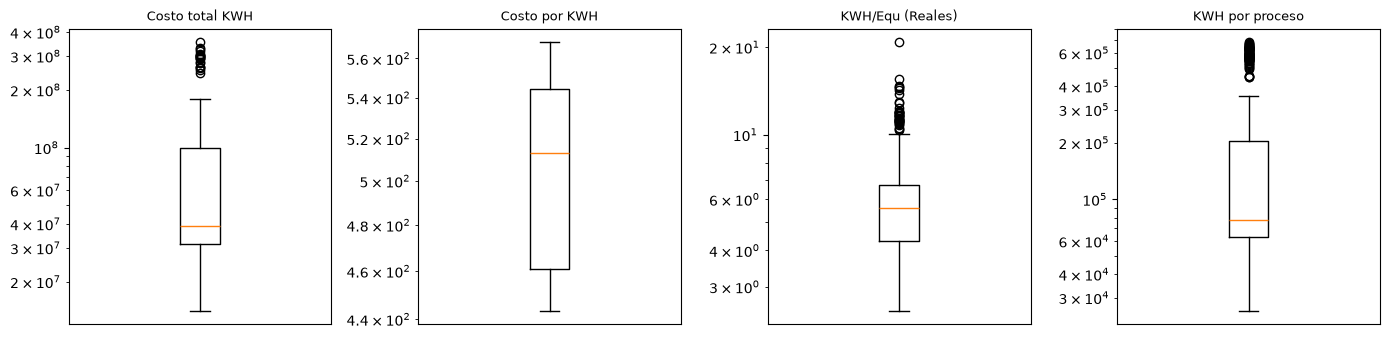

In [29]:
# Mismo analisis que arriba, ahora sobre el dataset sin el registro extremo
for col in cols:
    s = df_sin_extremo.loc[df_sin_extremo[col] > 0, col].dropna()
    print(
        f"{col:<22} mediana={s.median():>14,.1f}  max={s.max():>14,.1f}  "
        f"ordenes={np.log10(s.max() / s.median()):.2f}"
    )

fig, axes = plt.subplots(1, len(cols), figsize=(14, 3.5))
for ax, col in zip(axes, cols, strict=False):
    ax.boxplot(df_sin_extremo.loc[df_sin_extremo[col] > 0, col].dropna())
    ax.set_yscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [30]:
# Ya no hace falta fijar el estado 'antes' a mano: la auditoria corre sobre df_orec,
# que no se modifica, asi que las dos mitades de la comparacion se calculan aqui.
def ordenes(d: pd.DataFrame, col: str) -> float:
    """Ordenes de magnitud entre el maximo y la mediana de `col`, sobre valores > 0."""
    s = d.loc[d[col] > 0, col].dropna()
    return np.log10(s.max() / s.median())


comparacion = pd.DataFrame(
    [
        {
            "columna": col,
            "ordenes_antes": round(ordenes(df_orec, col), 2),
            "ordenes_despues": round(ordenes(df_sin_extremo, col), 2),
            "solucionado": ordenes(df_sin_extremo, col) < 1,  # criterio: < 1 orden
        }
        for col in cols
    ]
)
comparacion

,columna,ordenes_antes,ordenes_despues,solucionado
0,Costo total KWH,0.96,0.96,True
1,Costo por KWH,0.04,0.04,True
2,KWH/Equ (Reales),2.23,0.57,True
3,KWH por proceso,0.95,0.95,True


In [31]:
# Metricas explicitas del resumen de abajo.
# El 'antes' es df_orec completo y el 'despues' la copia sin el registro
# extremo: la auditoria de calidad mira todo el historico, no solo el train.
antes = df_orec
despues = df_sin_extremo


def resumen_iqr(d: pd.DataFrame) -> pd.DataFrame:
    """Tabla IQR por columna: atipicos, maximo, razon max/mediana y ordenes."""
    filas = []
    for col in cols:
        s = d[col].dropna()
        s = s[s > 0]
        q1, q3 = s.quantile([0.25, 0.75])
        atipicos = s[s > q3 + 1.5 * (q3 - q1)]
        filas.append(
            {
                "columna": col,
                "atipicos": len(atipicos),
                "maximo": s.max(),
                "ratio": s.max() / s.median(),
                "ordenes": np.log10(s.max() / s.median()),
            }
        )
    return pd.DataFrame(filas).set_index("columna")


a, b = resumen_iqr(antes), resumen_iqr(despues)
metricas_verificacion = (
    a.join(b, lsuffix="_antes", rsuffix="_despues")
    .assign(solucionado=lambda t: t["ordenes_despues"] < 1)
    .reset_index()
    .round(2)
)
print(f"filas: {len(antes)} -> {len(despues)} (se elimino {len(antes) - len(despues)})")
metricas_verificacion

filas: 567 -> 566 (se elimino 1)


,columna,atipicos_antes,maximo_antes,ratio_antes,ordenes_antes,atipicos_despues,maximo_despues,ratio_despues,ordenes_despues,solucionado
0,Costo total KWH,20,3.541321e+08,9.17,0.96,20,3.541321e+08,9.12,0.96,True
1,Costo por KWH,0,5.684600e+02,1.11,0.04,0,5.684600e+02,1.11,0.04,True
2,KWH/Equ (Reales),38,9.440500e+02,168.60,2.23,37,2.081000e+01,3.72,0.57,True
3,KWH por proceso,75,6.847130e+05,8.84,0.95,75,6.847130e+05,8.83,0.95,True


### Verificacion: el problema de la columna quedo resuelto

- **`KWH/Equ (Reales)` corregida.** Pasa de **2.23 a 0.57 ordenes** de magnitud, y la
  razon max/mediana cae de **168.6x a 3.7x**. Queda por debajo del umbral de 1 orden, en
  linea con las otras tres columnas.
- **El nuevo maximo es 20.8**, en linea con el resto de la distribucion: ya no hay un
  salto aislado respecto al segundo valor mas alto.
- **Las otras tres columnas no se vieron afectadas.** Se elimino 1 fila de 567, y
  `Costo por KWH` (0.04), `KWH por proceso` (0.95) y `Costo total KWH` (0.96) quedan
  identicos. La eliminacion fue quirurgica.
- **Quedan 37 atipicos** por IQR en la columna, pero son cola normal de la distribucion,
  no un problema de escala: ese era el punto a resolver.


## Series de tiempo de las variables numericas

La base solo tiene `Año` y `Mes`: la columna `Fecha` reparte los registros entre los dias
del mes de forma artificial, asi que la granularidad real es **mensual**. Cada punto es el
promedio de los 7 procesos de ese mes. La serie llega hasta **2026-06**, el ultimo mes de
la base.

Estas secciones usan **todo el historico**, no solo la ventana de train: son
descriptivas, no alimentan ningun modelo, y el deterioro que analizan ocurre justo en
2025-2026. La banda gris de cada grafico marca la ventana de test (desde `2025-01`),
para que se vea que parte de la serie quedo fuera del entrenamiento.


In [32]:
num_cols = [
    "Indice",
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

# Granularidad real = mensual; promedio entre los 7 procesos de cada mes.
# Fecha reparte el dia dentro del mes de forma artificial, asi que se agrupa por el
# inicio de mes. No hace falta recortar la cola: 2026-06 trae sus 7 filas.
mes_completo = df_orec["Fecha"].dt.to_period("M").dt.to_timestamp()
serie = df_orec.groupby(mes_completo)[num_cols].mean()

serie.shape

(81, 8)

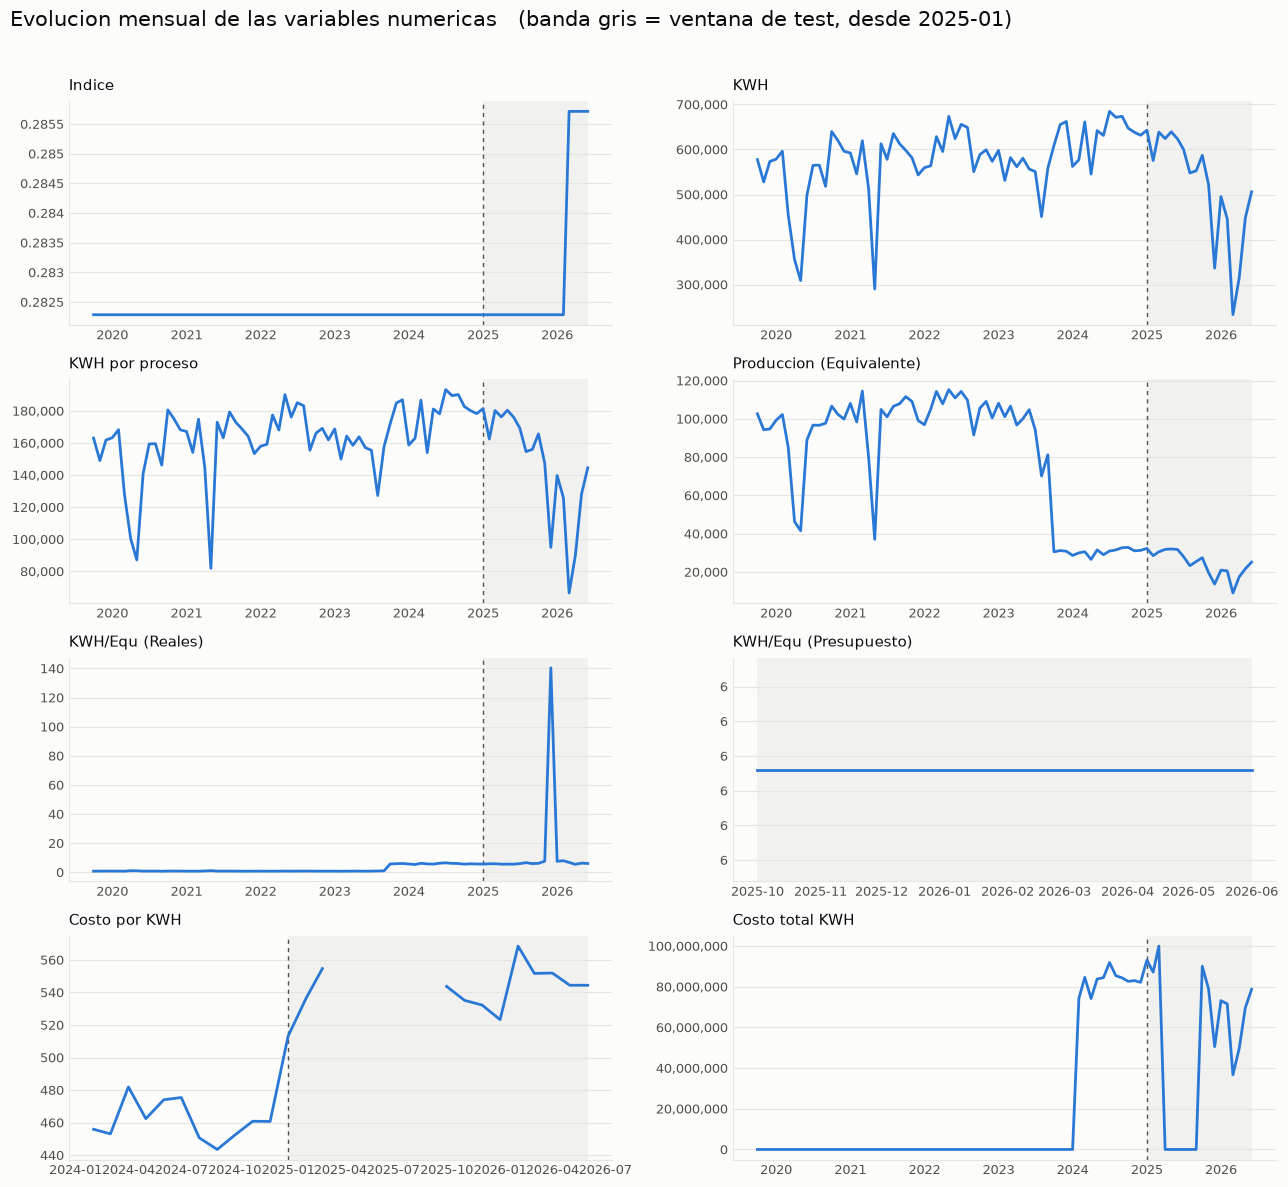

In [33]:
# Paleta validada (skill dataviz): linea, superficie, tinta y grilla
LINEA, SUPERFICIE = "#2a78d6", "#fcfcfb"
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e5e5e2"

# Las series cubren todo el historico, pero el split es temporal: esta funcion sombrea
# la ventana de test para que se vea que parte quedo fuera del entrenamiento.
# CORTE viene de la celda del split, asi la banda sigue al corte y no se repite el dato.
CORTE_TS = pd.Timestamp(CORTE)


def marcar_test(
    ax: plt.Axes, desde: pd.Timestamp, hasta: pd.Timestamp, etiqueta: bool = False
) -> None:
    """Sombrea la ventana de test, recortada al rango que ya ocupa la serie."""
    # El rango se pasa explicito: ax.get_xlim() devuelve numeros de fecha de matplotlib
    # y mezclarlos con un Timestamp en axvspan falla. Recortar a [desde, hasta] evita
    # que la banda estire el eje de un panel cuyos datos empiezan despues del corte
    # (KWH/Equ (Presupuesto) arranca en 2025-10, ya dentro de test).
    if hasta < CORTE_TS:
        return  # el panel termina antes del corte: no hay ventana de test que marcar
    ax.axvspan(max(CORTE_TS, desde), hasta, color=GRILLA, alpha=0.45, zorder=0, linewidth=0)
    if desde <= CORTE_TS:
        ax.axvline(CORTE_TS, color=TINTA_SUAVE, linewidth=1, linestyle=(0, (3, 3)), zorder=2)
    if etiqueta:
        ax.annotate(
            "ventana de test",
            xy=(CORTE_TS, 1),
            xycoords=("data", "axes fraction"),
            xytext=(5, -12),
            textcoords="offset points",
            color=TINTA_SUAVE,
            fontsize=8,
        )


fig, axes = plt.subplots(4, 2, figsize=(13, 12), facecolor=SUPERFICIE)
fig.suptitle(
    "Evolucion mensual de las variables numericas   (banda gris = ventana de test, desde 2025-01)",
    fontsize=15,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)

for ax, col in zip(axes.ravel(), num_cols, strict=False):
    ax.plot(serie.index, serie[col], color=LINEA, linewidth=2, zorder=3)
    visible = serie[col].replace(0, np.nan).dropna()
    marcar_test(ax, visible.index[0], visible.index[-1])
    ax.set_title(col, fontsize=10.5, color=TINTA, loc="left", pad=8)
    ax.set_facecolor(SUPERFICIE)
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}" if abs(v) >= 1 else f"{v:g}")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [34]:
# Metricas explicitas del resumen de abajo
mes = df_orec["Fecha"].dt.to_period("M").dt.to_timestamp()

# 1) Cobertura: desde cuando hay dato y en cuantos meses
cobertura = pd.DataFrame(
    [
        {
            "variable": c,
            "desde": mes[df_orec[c] > 0].min(),
            "meses_con_dato": mes[df_orec[c] > 0].nunique(),
            "meses_totales": mes.nunique(),
        }
        for c in num_cols
    ]
)

# 2) Calendario: con los diciembres corregidos no quedan huecos ni meses incompletos
meses = sorted(mes.unique())
esperados = pd.date_range(min(meses), max(meses), freq="MS")
print(
    f"meses {len(meses)} de {len(esperados)} esperados -> "
    f"sin huecos: {len(meses) == len(esperados)}"
)
filas_por_mes = mes.value_counts()
print(
    f"de {min(meses):%Y-%m} a {max(meses):%Y-%m} | "
    f"filas por mes: minimo {filas_por_mes.min()}, maximo {filas_por_mes.max()}"
)

# 3) Las dos agregaciones lado a lado: promedio por proceso vs total de planta (OREC)
por_proceso = df_orec.groupby(mes)[["KWH", "Produccion (Equivalente)", "KWH/Equ (Reales)"]].mean()
solo_orec = df_orec[df_orec["Proceso "].str.strip() == "OREC"].copy()
orec_mes = solo_orec["Fecha"].dt.to_period("M").dt.to_timestamp()
planta_ts = solo_orec.groupby(orec_mes)[
    ["KWH por proceso", "Produccion (Equivalente)", "KWH"]
].mean()
planta_ts["KWH/Equ"] = planta_ts["KWH por proceso"] / planta_ts["Produccion (Equivalente)"]


def cambio(serie: pd.Series, a: int = 2020, b: int = 2025) -> tuple[float, float, float]:
    """Media de `serie` en los anios `a` y `b`, y el cambio porcentual entre ambas."""
    x, y = serie.loc[str(a)].mean(), serie.loc[str(b)].mean()
    return x, y, 100 * (y - x) / x


filas = []
for etiqueta, serie in [
    ("promedio por proceso | KWH", por_proceso["KWH"]),
    ("promedio por proceso | Produccion", por_proceso["Produccion (Equivalente)"]),
    ("promedio por proceso | KWH/Equ", por_proceso["KWH/Equ (Reales)"]),
    ("planta OREC | KWH por proceso", planta_ts["KWH por proceso"]),
    ("planta OREC | Equivalentes", planta_ts["Produccion (Equivalente)"]),
    ("planta OREC | KWH/Equ", planta_ts["KWH/Equ"]),
    ("planta OREC | KWH", planta_ts["KWH"]),
]:
    a, b, pct = cambio(serie)
    filas.append({"medida": etiqueta, "media_2020": a, "media_2025": b, "cambio_pct": pct})

metricas_series = pd.DataFrame(filas).round(1)
display(cobertura)
metricas_series

meses 81 de 81 esperados -> sin huecos: True
de 2019-10 a 2026-06 | filas por mes: minimo 7, maximo 7


,variable,desde,meses_con_dato,meses_totales
0,Indice,2019-10-01,81,81
1,KWH,2019-10-01,81,81
2,KWH por proceso,2019-10-01,81,81
3,Produccion (Equivalente),2019-10-01,81,81
4,KWH/Equ (Reales),2019-10-01,81,81
5,KWH/Equ (Presupuesto),2025-10-01,9,81
6,Costo por KWH,2024-02-01,23,81
7,Costo total KWH,2024-02-01,23,81


,medida,media_2020,media_2025,cambio_pct
0,promedio por proceso | KWH,524578.2,574161.8,9.5
1,promedio por proceso | Produccion,88612.4,27025.4,-69.5
2,promedio por proceso | KWH/Equ,0.9,17.3,1893.1
3,planta OREC | KWH por proceso,524578.2,574161.8,9.5
4,planta OREC | Equivalentes,88612.4,94589.1,6.7
5,planta OREC | KWH/Equ,6.1,6.2,2.0
6,planta OREC | KWH,524578.2,574161.8,9.5


### Resumen de las series de tiempo

**1. Cada metrica empieza en una fecha distinta.** Esto explica los ceros y nulos que
aparecieron en la seccion de atipicos: no eran datos perdidos, la metrica simplemente aun
no se registraba.

| variable | desde | meses con dato |
|---|---|---|
| `Indice`, `KWH`, `KWH por proceso`, `Produccion (Equivalente)`, `KWH/Equ (Reales)` | 2019-10 | 81 / 81 |
| `Costo por KWH`, `Costo total KWH` | **2024-02** | 23 / 81 |
| `KWH/Equ (Presupuesto)` | **2025-10** | 9 / 81 |

**2. El consumo se mantuvo, la produccion se desplomo** (promedios anuales):

| variable | 2020 | 2025 | cambio |
|---|---|---|---|
| `KWH` | 524,578.2 | 574,161.8 | **+9.5 %** |
| `Produccion (Equivalente)` | 88,612.4 | 27,025.4 | **-69.5 %** |
| `KWH/Equ (Reales)` | 0.9 | 17.3 | **+1893 %** |

Se gasta practicamente la misma energia para producir un tercio: por eso la energia por
unidad equivalente se multiplico ~19x. Esto reencuadra el analisis de atipicos: la
dispersion de `KWH/Equ (Reales)` no es solo ruido, hay una tendencia real detras.

> esto cambia al usar solo el reporte global de planta, es solo un error de agregación

**3. Cobertura.** La serie va de 2019-10 a 2026-06: 81 meses sin huecos de calendario, con
7 filas cada uno. La fila de planta de cada diciembre venia rotulada con el año siguiente
(por eso parecia haber un registro suelto en 2026-12 y faltar uno en 2019-12); se corrigio
antes de repartir los dias.


## Crecimiento de la energia por bateria producida

La fila `OREC` de cada mes es el **total de planta**, no un proceso mas: los otros 6
procesos suman el 97.6 % de ella y solo `OREC` reporta produccion en los 81 meses. A nivel
de planta se cumple exactamente:

`KWH/Equ (Reales) = KWH por proceso / Produccion (Equivalente)`

Las tres magnitudes viven en escalas muy distintas (~500,000 kWh, ~88,000 equivalentes,
~5.9 de razon), asi que se indexan a base 100 para compararlas en un solo eje.


In [35]:
# Solo la fila OREC = total de planta (los 6 subprocesos son su desglose).
# Se indexa por inicio de mes: Fecha reparte el dia de forma artificial.
planta = df_orec[df_orec["Proceso "].str.strip() == "OREC"].copy()
planta["Mes_inicio"] = planta["Fecha"].dt.to_period("M").dt.to_timestamp()
planta = planta.set_index("Mes_inicio").sort_index()

# Media movil de 12 meses: quita la estacionalidad para poder leer el crecimiento.
# La razon se calcula sobre las series ya suavizadas (nunca el promedio de razones),
# asi el indice combinado cierra exacto.
energia = planta["KWH por proceso"].rolling(12).mean()
equiv = planta["Produccion (Equivalente)"].rolling(12).mean()
razon = energia / equiv

# Indice base 100 en la primera ventana completa, no en un mes suelto
idx = pd.DataFrame(
    {
        "Energia (KWH)": 100 * energia / energia.dropna().iloc[0],
        "Equivalentes": 100 * equiv / equiv.dropna().iloc[0],
        "KWH/Equ": 100 * razon / razon.dropna().iloc[0],
    }
).dropna()

# La curva combinada: KWH/Equ indexado == 100 * Energia_idx / Equivalentes_idx
idx["KWH/Equ (calculada)"] = 100 * idx["Energia (KWH)"] / idx["Equivalentes"]

assert np.allclose(idx["KWH/Equ"], idx["KWH/Equ (calculada)"]), "la identidad no cierra"
print(
    f"{len(planta)} meses de planta | indice desde {idx.index[0]:%Y-%m} hasta {idx.index[-1]:%Y-%m}"
)
idx.tail(3).round(2)

81 meses de planta | indice desde 2020-09 hasta 2026-06


,Energia (KWH),Equivalentes,KWH/Equ,KWH/Equ (calculada)
Mes_inicio,,,,
2026-04-01,96.40,89.21,108.06,108.06
2026-05-01,93.27,84.71,110.11,110.11
2026-06-01,91.35,81.30,112.36,112.36


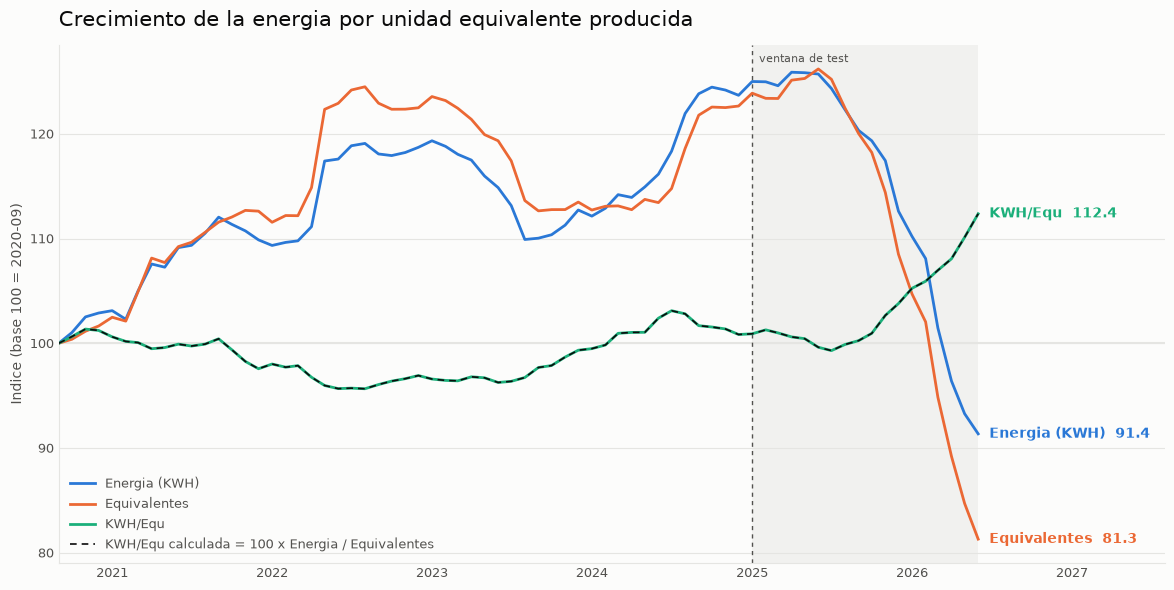

In [36]:
# Paleta validada (skill dataviz, slots 1-3, --pairs all)
C_ENERGIA, C_EQUIV, C_RAZON = "#2a78d6", "#eb6834", "#1baf7a"
SUPERFICIE, TINTA, TINTA_SUAVE, GRILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e5e2"

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SUPERFICIE)
ax.set_facecolor(SUPERFICIE)

ax.axhline(100, color=GRILLA, linewidth=1.5, zorder=1)
series = [
    ("Energia (KWH)", C_ENERGIA),
    ("Equivalentes", C_EQUIV),
    ("KWH/Equ", C_RAZON),
]
for nombre, color in series:
    ax.plot(idx.index, idx[nombre], color=color, linewidth=2, label=nombre, zorder=3)

# Curva combinada calculada: debe caer exactamente sobre KWH/Equ medido
ax.plot(
    idx.index,
    idx["KWH/Equ (calculada)"],
    color=TINTA,
    linewidth=1.2,
    linestyle=(0, (4, 3)),
    zorder=4,
    label="KWH/Equ calculada = 100 x Energia / Equivalentes",
)

# Etiquetas directas (obligatorias: el verde queda por debajo de 3:1 de contraste)
for nombre, color in series:
    y = idx[nombre].iloc[-1]
    ax.annotate(
        f"{nombre}  {y:,.1f}",
        xy=(idx.index[-1], y),
        xytext=(8, 0),
        textcoords="offset points",
        color=color,
        fontsize=10,
        fontweight="bold",
        va="center",
    )

# La banda queda dentro de los datos; las etiquetas directas viven en el margen
# de 14 meses que anade set_xlim, asi que no se solapan con ella.
marcar_test(ax, idx.index[0], idx.index[-1], etiqueta=True)

ax.set_title(
    "Crecimiento de la energia por unidad equivalente producida",
    fontsize=15,
    color=TINTA,
    loc="left",
    pad=14,
)
ax.set_ylabel(f"Indice (base 100 = {idx.index[0]:%Y-%m})", fontsize=10, color=TINTA_SUAVE)
ax.grid(axis="y", color=GRILLA, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRILLA)
ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
ax.set_xlim(idx.index[0], idx.index[-1] + pd.DateOffset(months=14))
ax.legend(loc="lower left", frameon=False, fontsize=9, labelcolor=TINTA_SUAVE)

plt.tight_layout()
plt.show()

In [37]:
# Metricas explicitas del resumen de abajo
base, final = idx.iloc[0], idx.iloc[-1]
niveles = {"Energia (KWH)": energia, "Equivalentes": equiv, "KWH/Equ": razon}

metricas_energia = pd.DataFrame(
    [
        {
            "serie": nombre,
            "nivel_base": s.dropna().iloc[0],
            "nivel_final": s.dropna().iloc[-1],
            "indice": final[nombre],
            "cambio_pct": final[nombre] - 100,
        }
        for nombre, s in niveles.items()
    ]
).round(2)

# La identidad de la curva combinada, verificada y no asumida
identidad_ok = np.allclose(idx["KWH/Equ"], 100 * idx["Energia (KWH)"] / idx["Equivalentes"])
print(f"base={idx.index[0]:%Y-%m}  final={idx.index[-1]:%Y-%m}  identidad_exacta={identidad_ok}")
metricas_energia

base=2020-09  final=2026-06  identidad_exacta=True


,serie,nivel_base,nivel_final,indice,cambio_pct
0,Energia (KWH),509858.83,465758.08,91.35,-8.65
1,Equivalentes,87179.78,70875.80,81.30,-18.70
2,KWH/Equ,5.85,6.57,112.36,12.36


### Resumen: la energia por bateria sube, pero no por gastar mas

Serie de planta (`OREC`), media movil de 12 meses, indice base 100 en 2020-09:

| serie | nivel base (2020-09) | nivel final (2026-06) | indice |
|---|---|---|---|
| Energia | 509,859 kWh/mes | 465,758 kWh/mes | **91.35** |
| Equivalentes | 87,180 | 70,876 | **81.30** |
| `KWH/Equ` | 5.85 | 6.57 | **112.36** |

**El consumo de energia bajo 8.65 %.** Aun asi la energia por unidad equivalente subio
**12.36 %**, porque la produccion cayo mas rapido: **-18.70 %**. La planta no esta gastando
mas energia, esta sacando menos producto por cada kWh. Una sola linea de `KWH/Equ` mostraria
la subida pero no la causa; la descomposicion separa las dos cosas.

**La curva combinada cierra exacta.** La linea punteada es `100 x Energia_idx /
Equivalentes_idx` y cae encima de la medida (el `assert` de la celda anterior lo verifica).
No es una aproximacion: es la misma identidad `KWH/Equ = energia / equivalentes` leida en
forma de indices.

Notas de metodo: la media movil de 12 meses descarta los primeros 11 meses, por eso la
serie arranca en 2020-09. La razon se calcula sobre las series suavizadas, no promediando
razones mensuales, que daria un numero distinto.


## Series de tiempo por proceso

Solo 3 de las 8 variables varian entre procesos: `KWH por proceso`,
`Produccion (Equivalente)` y `KWH/Equ (Reales)`. Las otras (`KWH`, los costos,
`KWH/Equ (Presupuesto)`, `Indice`) son valores de planta repetidos en las 7 filas
del mes, asi que separarlas por proceso daria 7 paneles identicos.


In [38]:
VARS_PROC = ["KWH por proceso", "Produccion (Equivalente)", "KWH/Equ (Reales)"]

# Fecha reparte el dia dentro del mes de forma artificial: se trabaja por inicio de mes
base_proc = df_orec.copy()
base_proc["Proceso"] = base_proc["Proceso "].str.strip()
base_proc["Mes"] = base_proc["Fecha"].dt.to_period("M").dt.to_timestamp()

# OREC es el total de planta: va primero, luego los 6 subprocesos
PROCESOS = ["OREC", *sorted(set(base_proc["Proceso"]) - {"OREC"})]

# Un DataFrame Mes x Proceso por cada variable
series_proc = {
    v: base_proc.pivot_table(index="Mes", columns="Proceso", values=v, aggfunc="mean")[PROCESOS]
    for v in VARS_PROC
}
print(f"{len(PROCESOS)} procesos | {len(series_proc[VARS_PROC[0]])} meses")
series_proc["KWH por proceso"].tail(3).round(1)

7 procesos | 81 meses


Proceso,OREC,Cinta,Empaste Casting,Empaste Cominco,Empaste Expanded,Planta Oxido,Rejillas
Mes,,,,,,,
2026-04-01,315157.5,40970.5,34667.3,50425.2,0.0,135517.7,53576.8
2026-05-01,448000.0,58240.0,49280.0,71680.0,0.0,192640.0,76160.0
2026-06-01,506000.0,65780.0,55660.0,80960.0,0.0,217580.0,86020.0


In [39]:
series_proc.keys()

dict_keys(['KWH por proceso', 'Produccion (Equivalente)', 'KWH/Equ (Reales)'])

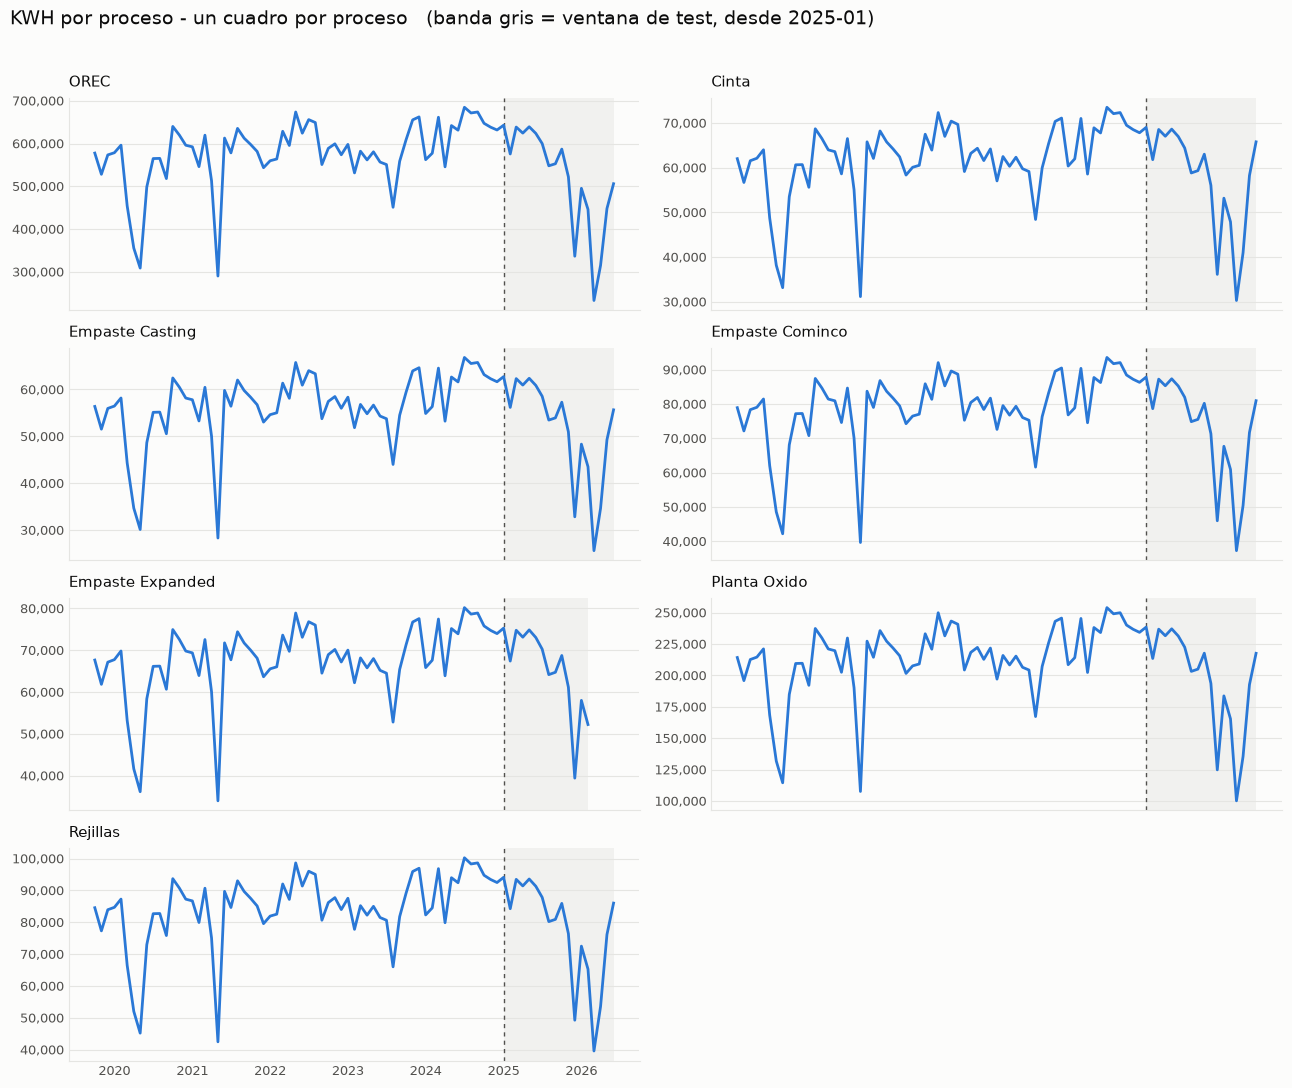

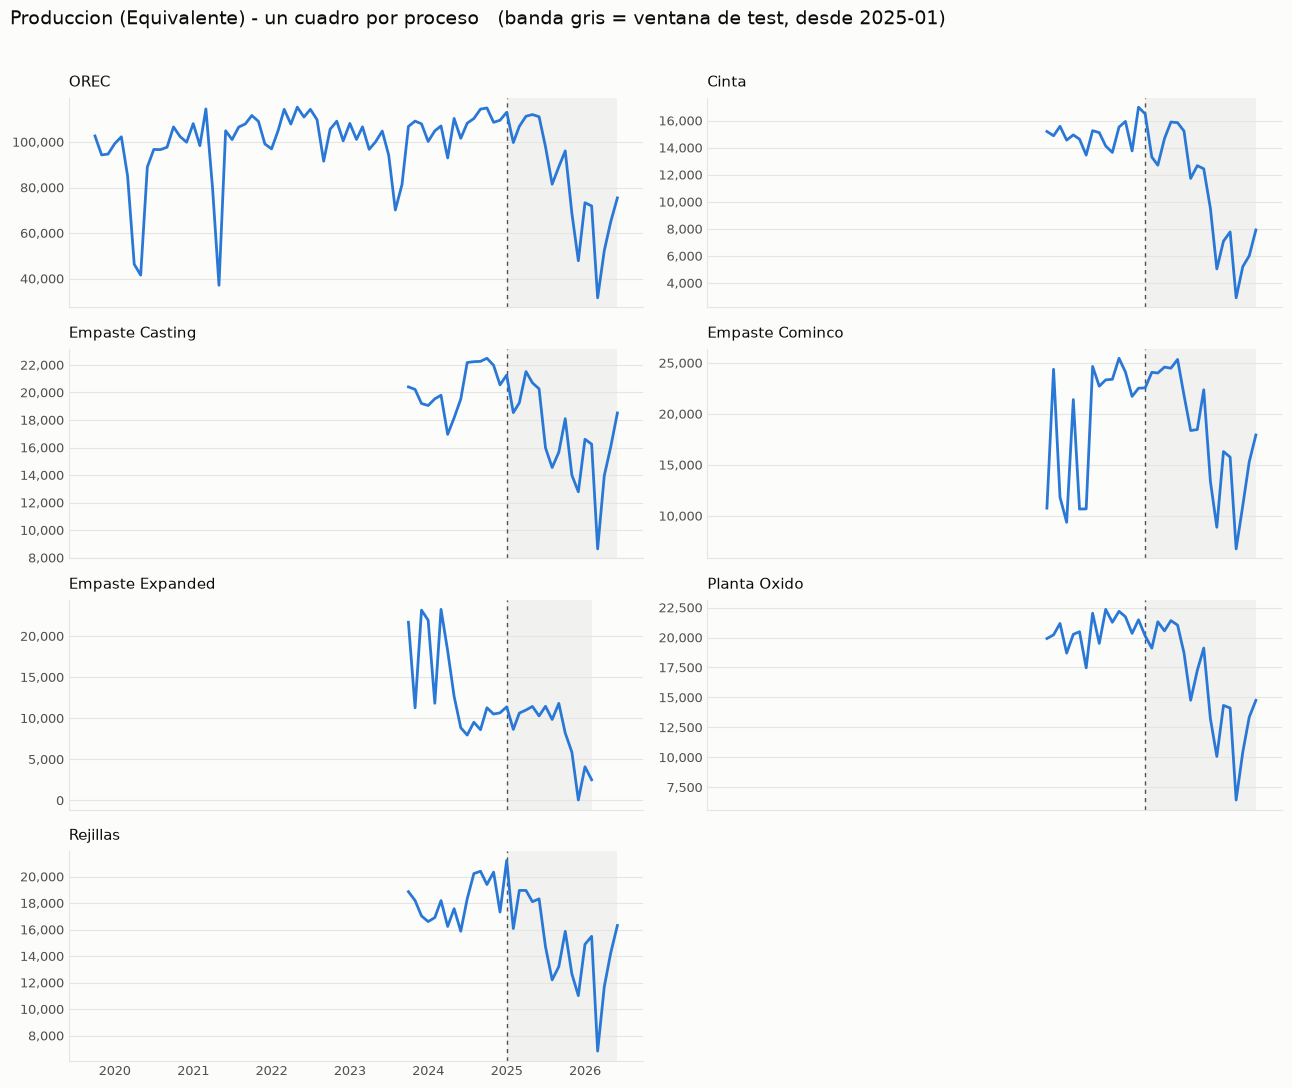

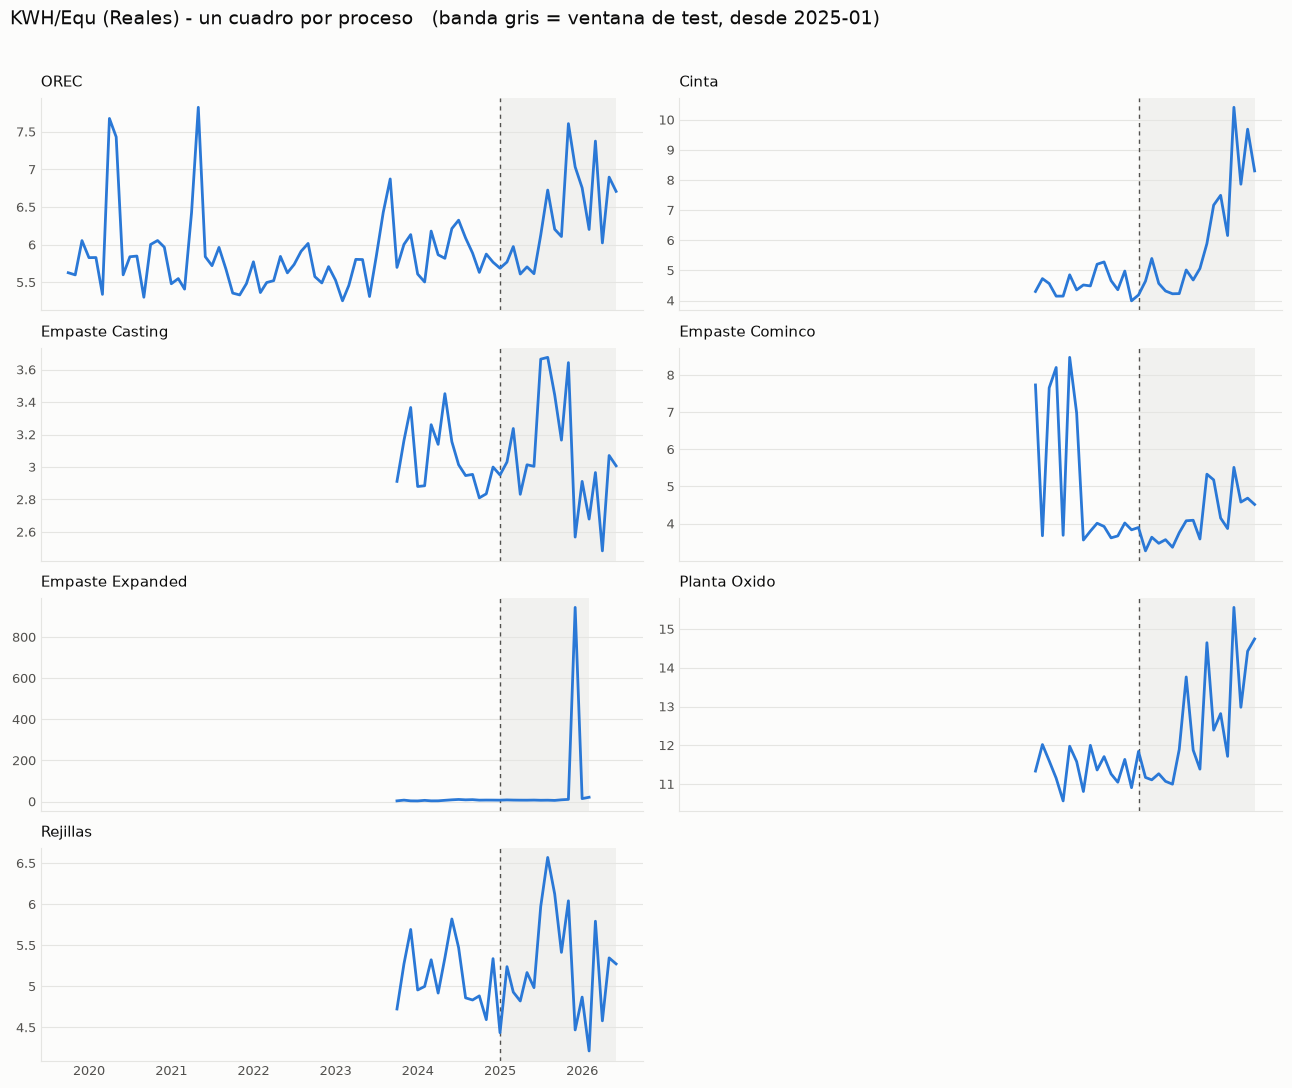

In [40]:
# Paleta validada (skill dataviz)
LINEA, SUPERFICIE = "#2a78d6", "#fcfcfb"
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e5e5e2"

# Por encima de este valor el eje se formatea con separador de miles y sin decimales
UMBRAL_MILES = 1000


def rejilla_procesos(titulo: str) -> tuple[plt.Figure, np.ndarray]:
    """Rejilla 4x2 con un cuadro por proceso (7 procesos, la 8a casilla se oculta)."""
    fig, axes = plt.subplots(4, 2, figsize=(13, 11), facecolor=SUPERFICIE, sharex=True)
    fig.suptitle(
        f"{titulo}   (banda gris = ventana de test, desde 2025-01)",
        fontsize=14,
        color=TINTA,
        x=0.01,
        ha="left",
        y=0.985,
    )
    for ax in axes.ravel():
        ax.set_facecolor(SUPERFICIE)
        ax.grid(axis="y", color=GRILLA, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color(GRILLA)
        ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
        ax.yaxis.set_major_formatter(
            lambda v, _: f"{v:,.0f}" if abs(v) >= UMBRAL_MILES else f"{v:,.3g}"
        )
    axes.ravel()[-1].set_visible(False)
    return fig, axes


# Una figura por variable; dentro, un cuadro por proceso
for var in VARS_PROC:
    tabla = series_proc[var]
    fig, axes = rejilla_procesos(f"{var} - un cuadro por proceso")
    for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
        s = tabla[proc].replace(0, np.nan)  # el cero aqui es 'no se registraba'
        ax.plot(s.index, s, color=LINEA, linewidth=2, zorder=3)
        ax.set_title(proc, fontsize=10.5, color=TINTA, loc="left", pad=8)
    # sharex=True: todos los cuadros comparten el eje, se sombrea una vez por eje
    for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
        s = tabla[proc].replace(0, np.nan).dropna()
        if not s.empty:
            marcar_test(ax, s.index[0], s.index[-1])
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

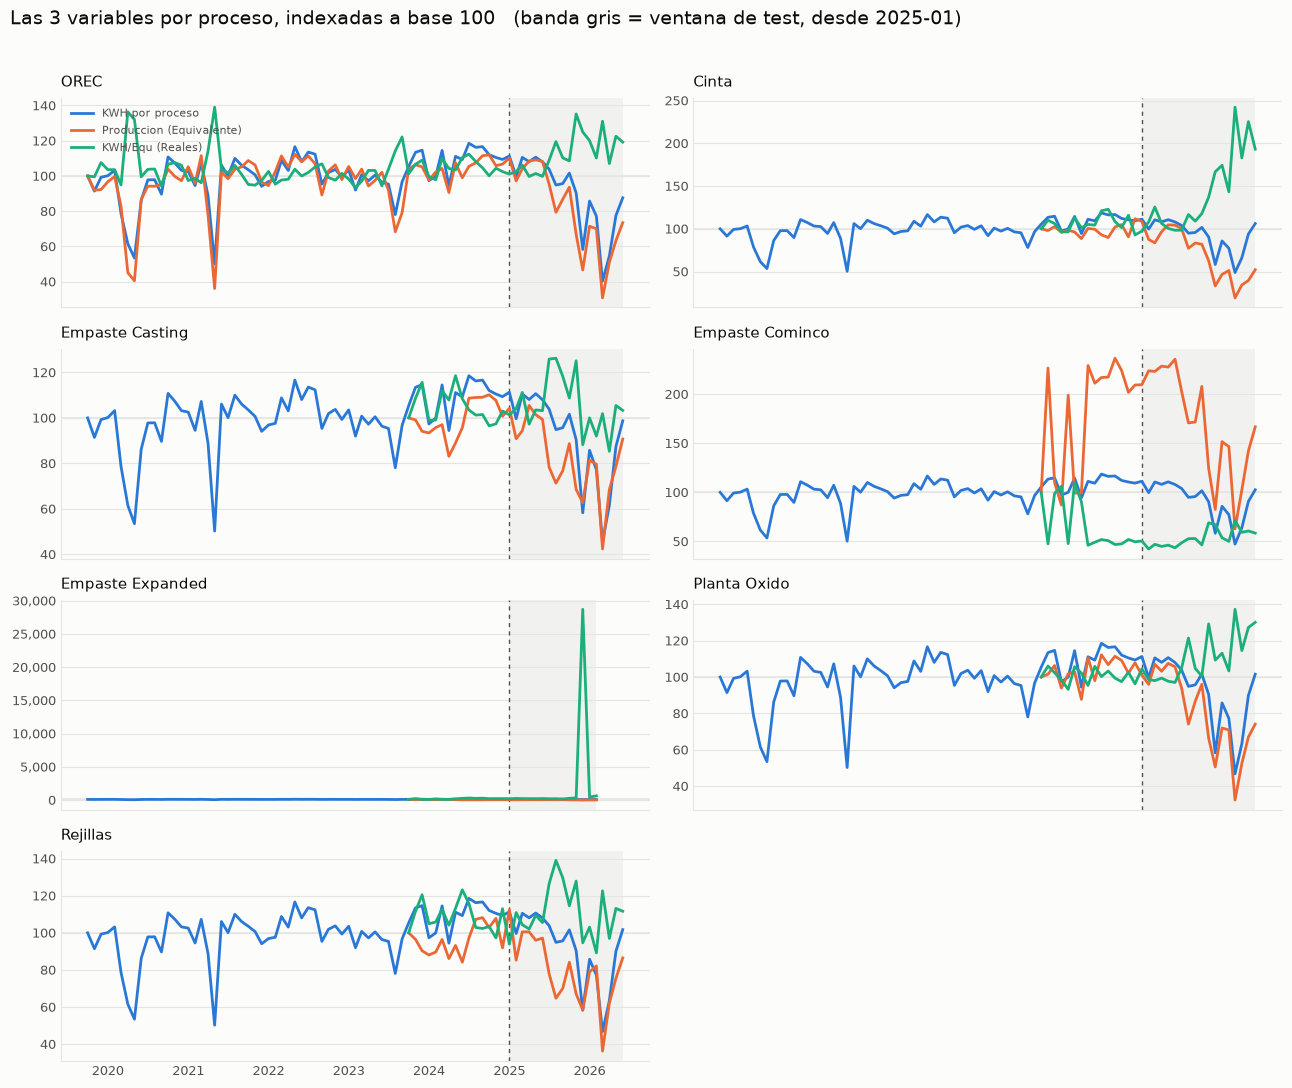

In [41]:
# Cuarta figura: un cuadro por proceso con las 3 variables indexadas a base 100,
# unica forma de verlas juntas (escalas de ~10^5, ~10^4 y ~5)
C_ENERGIA, C_EQUIV, C_RAZON = "#2a78d6", "#eb6834", "#1baf7a"

fig, axes = rejilla_procesos("Las 3 variables por proceso, indexadas a base 100")
for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    for var, color in zip(VARS_PROC, [C_ENERGIA, C_EQUIV, C_RAZON], strict=False):
        s = series_proc[var][proc].replace(0, np.nan).dropna()
        if s.empty:
            continue
        ax.plot(s.index, 100 * s / s.iloc[0], color=color, linewidth=2, label=var, zorder=3)
    ax.axhline(100, color=GRILLA, linewidth=1.2, zorder=1)
    ax.set_title(proc, fontsize=10.5, color=TINTA, loc="left", pad=8)

for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    vistos = [series_proc[v][proc].replace(0, np.nan).dropna() for v in VARS_PROC]
    vistos = [s for s in vistos if not s.empty]
    if vistos:
        marcar_test(ax, min(s.index[0] for s in vistos), max(s.index[-1] for s in vistos))

axes.ravel()[0].legend(loc="upper left", frameon=False, fontsize=8, labelcolor=TINTA_SUAVE)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [42]:
# Metricas explicitas del resumen de abajo
filas = []
for proc in PROCESOS:
    fila = {"proceso": proc}
    for var in VARS_PROC:
        s = series_proc[var][proc].replace(0, np.nan).dropna()
        fila[f"{var} | meses"] = len(s)
        fila[f"{var} | desde"] = s.index.min().strftime("%Y-%m") if len(s) else "-"
    filas.append(fila)

metricas_series_proc = pd.DataFrame(filas)
metricas_series_proc

,proceso,KWH por proceso | meses,KWH por proceso | desde,Produccion (Equivalente) | meses,Produccion (Equivalente) | desde,KWH/Equ (Reales) | meses,KWH/Equ (Reales) | desde
0,OREC,81,2019-10,81,2019-10,81,2019-10
1,Cinta,81,2019-10,33,2023-10,33,2023-10
2,Empaste Casting,81,2019-10,33,2023-10,33,2023-10
3,Empaste Cominco,81,2019-10,33,2023-10,33,2023-10
4,Empaste Expanded,77,2019-10,29,2023-10,29,2023-10
5,Planta Oxido,81,2019-10,33,2023-10,33,2023-10
6,Rejillas,81,2019-10,33,2023-10,33,2023-10


### Resumen: series por proceso

- **Solo 3 variables varian por proceso.** `KWH`, los dos costos,
  `KWH/Equ (Presupuesto)` e `Indice` son cifras de planta repetidas en las 7 filas
  de cada mes.
- **La cobertura es muy despareja.** `KWH por proceso` existe en casi todos los
  meses (81; 77 en `Empaste Expanded`), pero `Produccion (Equivalente)` y
  `KWH/Equ (Reales)` solo existen desde **2024** en los subprocesos (33 meses, 29 en
  `Empaste Expanded`). `OREC` los tiene en los 81 meses porque es el total de planta.
- **Por eso los cuadros no empiezan a la vez.** El de `OREC` cubre 2019-2026 y los de
  los subprocesos arrancan en 2024: no es un hueco de datos, es cuando se empezo a
  medir produccion por proceso.


## Crecimiento de la energia por proceso

Misma descomposicion que a nivel de planta, ahora un cuadro por proceso. La ventana
de suavizado se adapta a la cobertura: **12 meses para `OREC`** (81 meses de
historia) y **3 meses para los subprocesos** (33 meses desde 2024), si no
quedarian en ~21 puntos.


In [43]:
# OREC reutiliza el indice ya calculado en la seccion de planta (`idx`), para que no
# existan dos cifras distintas de lo mismo en el notebook. Los subprocesos se calculan
# aparte con ventana de 3 meses, desde el primer mes con produccion registrada.
crecimiento = {
    "OREC": idx[["Energia (KWH)", "Equivalentes", "KWH/Equ"]].rename(
        columns={"Energia (KWH)": "Energia"}
    )
}

for proc in [x for x in PROCESOS if x != "OREC"]:
    e = series_proc["KWH por proceso"][proc]
    q = series_proc["Produccion (Equivalente)"][proc]
    inicio = q[q > 0].index.min()  # desde que se mide produccion en este proceso
    e, q = e.loc[inicio:].rolling(3).mean(), q.loc[inicio:].rolling(3).mean()
    comun = e.dropna().index.intersection(q.dropna().index)
    e, q = e.loc[comun], q.loc[comun]
    r = e / q
    crecimiento[proc] = pd.DataFrame(
        {
            "Energia": 100 * e / e.iloc[0],
            "Equivalentes": 100 * q / q.iloc[0],
            "KWH/Equ": 100 * r / r.iloc[0],
        }
    )

metricas_crecimiento_proc = pd.DataFrame(
    [
        {
            "proceso": proc,
            "ventana_meses": 12 if proc == "OREC" else 3,
            "puntos": len(tabla),
            "desde": tabla.index.min().strftime("%Y-%m"),
            "hasta": tabla.index.max().strftime("%Y-%m"),
            "KWH por proceso idx (final)": tabla["Energia"].iloc[-1],
            "Produccion (Equivalente) idx (final)": tabla["Equivalentes"].iloc[-1],
            "KWH/Equ idx (final)": tabla["KWH/Equ"].iloc[-1],
        }
        for proc, tabla in crecimiento.items()
    ]
).round(1)

# La identidad combinada tiene que cerrar en cada proceso
assert all(
    np.allclose(t["KWH/Equ"], 100 * t["Energia"] / t["Equivalentes"]) for t in crecimiento.values()
), "la identidad no cierra en algun proceso"
metricas_crecimiento_proc

,proceso,ventana_meses,puntos,desde,hasta,KWH por proceso idx (final),Produccion (Equivalente) idx (final),KWH/Equ idx (final)
0,OREC,12,70,2020-09,2026-06,91.4,81.3,112.4
1,Cinta,3,31,2023-12,2026-06,79.8,41.9,190.3
2,Empaste Casting,3,31,2023-12,2026-06,74.3,81.1,91.6
3,Empaste Cominco,3,31,2023-12,2026-06,77.2,94.2,81.9
4,Empaste Expanded,3,28,2023-12,2026-03,48.9,11.8,415.6
5,Planta Oxido,3,31,2023-12,2026-06,76.4,62.9,121.5
6,Rejillas,3,31,2023-12,2026-06,76.5,78.1,97.9


In [44]:
crecimiento.keys()

dict_keys(['OREC', 'Cinta', 'Empaste Casting', 'Empaste Cominco', 'Empaste Expanded', 'Planta Oxido', 'Rejillas'])

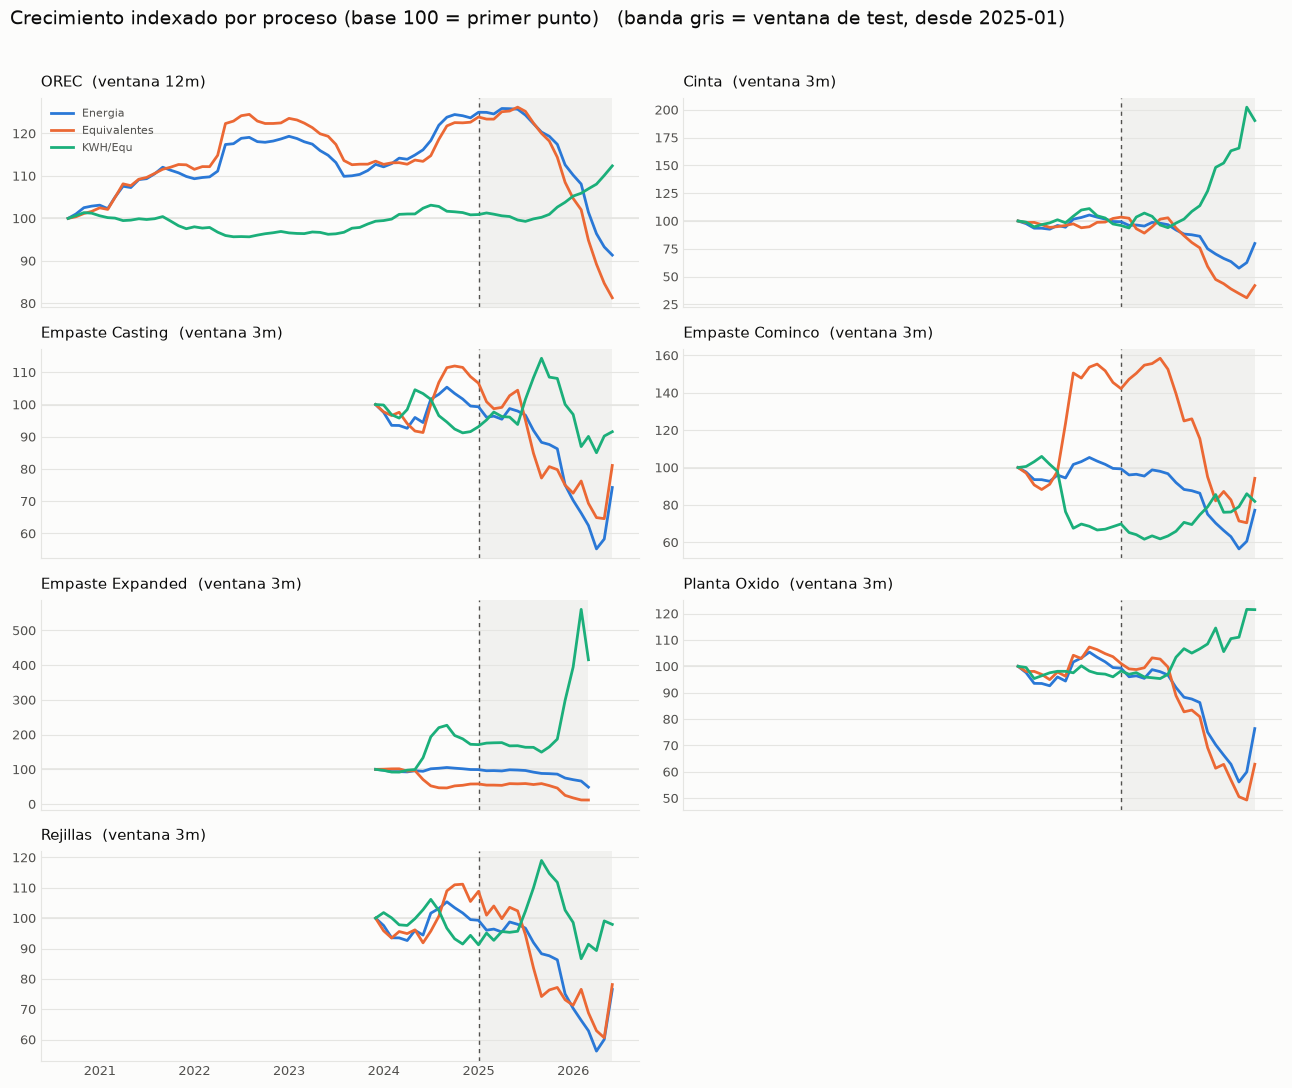

In [45]:
fig, axes = rejilla_procesos("Crecimiento indexado por proceso (base 100 = primer punto)")
for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    tabla = crecimiento[proc]
    for col, color in zip(
        ["Energia", "Equivalentes", "KWH/Equ"], [C_ENERGIA, C_EQUIV, C_RAZON], strict=False
    ):
        ax.plot(tabla.index, tabla[col], color=color, linewidth=2, label=col, zorder=3)
    ax.axhline(100, color=GRILLA, linewidth=1.2, zorder=1)
    # cada panel termina en una fecha distinta (Empaste Expanded para en 2026-03)
    marcar_test(ax, tabla.index[0], tabla.index[-1])
    ventana = 12 if proc == "OREC" else 3
    ax.set_title(f"{proc}  (ventana {ventana}m)", fontsize=10.5, color=TINTA, loc="left", pad=8)

axes.ravel()[0].legend(loc="upper left", frameon=False, fontsize=8, labelcolor=TINTA_SUAVE)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Resumen: crecimiento por proceso

| proceso | energia | equivalentes | KWH/Equ |
|---|---|---|---|
| `OREC` (planta, 12m) | 91.4 | 81.3 | **112.4** |
| `Cinta` | 79.8 | 41.9 | **190.3** |
| `Empaste Casting` | 74.3 | 81.1 | 91.6 |
| `Empaste Cominco` | 77.2 | 94.2 | **81.9** |
| `Empaste Expanded` | 48.9 | 11.8 | **415.6** |
| `Planta Oxido` | 76.4 | 62.9 | 121.5 |
| `Rejillas` | 76.5 | 78.1 | 97.9 |

- **Todos los procesos bajaron su consumo** (indices de 48.9 a 79.8, entre -20 % y
  -51 %). El problema nunca fue gastar mas energia.
- **Lo que decide el resultado es cuanto cayo la produccion.** `Empaste Cominco` casi
  la sostuvo (94.2) y mejoro su intensidad un 18 %; `Empaste Expanded` se desplomo a
  11.8 y su intensidad se multiplico por 4.2.
- **El +12.4 % de planta esconde comportamientos opuestos.** Tres procesos mejoraron
  (`Empaste Cominco`, `Empaste Casting`, `Rejillas`) y dos empeoraron fuerte (`Cinta`
  +90 %, `Empaste Expanded` +316 %). Ahi esta el margen de mejora, no en el promedio.
- Las ventanas no son comparables entre si: `OREC` cubre 2020-2026 con ventana de 12
  meses y los subprocesos desde 2023-12 con ventana de 3.


En general la planta y el desgloce por linea muestran como se bajo la producción y el consumo, sin embargo la producción baja mas rapido que el consumo de ahí que `KWH/Equ` aumente, esto es un posible problema en el cual se debe ahondar mas para buscar sus causas.


## Estacionalidad, tendencia y autocorrelacion

Se analizan las tres series mensuales de planta (fila `OREC`): energia, equivalentes y
`KWH/Equ`, con la fila de diciembre ya corregida. Los subprocesos no se analizan aparte:
su produccion solo tiene 33 meses, menos de 3 observaciones por mes del año, muy poco para
una prueba de estacionalidad.

Cada prueba se calcula en dos ventanas: **toda la historia** y **solo train** (hasta
2024-12). La segunda es la que puede usar un modelo; la primera muestra cuanto cambia el
diagnostico al incluir 2025-2026.

In [46]:
ALFA = 0.05  # nivel de significancia de todas las pruebas de la seccion
PERIODO = 12  # meses de un ciclo estacional
Z_CRITICO = stats.norm.ppf(1 - ALFA / 2)  # 1.96: ancho de la banda de ruido blanco

# Las tres series de planta, sobre el indice mensual que ya tiene `planta`
series_ts = {
    "Energia (KWH)": planta["KWH por proceso"],
    "Equivalentes": planta["Produccion (Equivalente)"],
    "KWH/Equ": planta["KWH por proceso"] / planta["Produccion (Equivalente)"],
}


def ventanas(s: pd.Series) -> dict[str, pd.Series]:
    """La serie completa y su tramo de train (antes del corte del split)."""
    return {"historia": s, "train": s[s.index < CORTE_TS]}


def sin_tendencia(s: pd.Series) -> pd.Series:
    """Razon entre la serie y su media movil centrada de 12 meses, en base 100."""
    # Una media de 12 meses cae entre dos meses; promediar dos consecutivas (2x12) la
    # centra en un mes. Se pierden 6 meses en cada extremo.
    tendencia = s.rolling(PERIODO, center=True).mean().rolling(2).mean().shift(-1)
    return (100 * s / tendencia).dropna()


def kruskal_por_grupo(valores: pd.Series, grupos: pd.Index) -> dict[str, float]:
    """Kruskal-Wallis de `valores` entre `grupos`, con su tamano de efecto eta2."""
    muestras = [g.to_numpy() for _, g in valores.groupby(grupos)]
    h, p = stats.kruskal(*muestras)
    n, k = len(valores), len(muestras)
    # eta2 = (H - k + 1) / (n - k): parte de la variabilidad de rangos que explican los
    # grupos. Bajo H0 ronda cero y puede salir negativa, por eso se acota en 0.
    return {"grupos": k, "n": n, "H": h, "p_valor": p, "eta2": max(0.0, (h - k + 1) / (n - k))}


resumen_ventanas = pd.DataFrame(
    [
        {
            "ventana": ventana,
            "meses": len(tramo),
            "desde": f"{tramo.index[0]:%Y-%m}",
            "hasta": f"{tramo.index[-1]:%Y-%m}",
            "observaciones por mes del anio (min)": tramo.groupby(tramo.index.month).size().min(),
            "sin tendencia: meses": len(sin_tendencia(tramo)),
        }
        for ventana, tramo in ventanas(series_ts["Energia (KWH)"]).items()
    ]
)
resumen_ventanas

,ventana,meses,desde,hasta,observaciones por mes del anio (min),sin tendencia: meses
0,historia,81,2019-10,2026-06,6,69
1,train,63,2019-10,2024-12,5,51


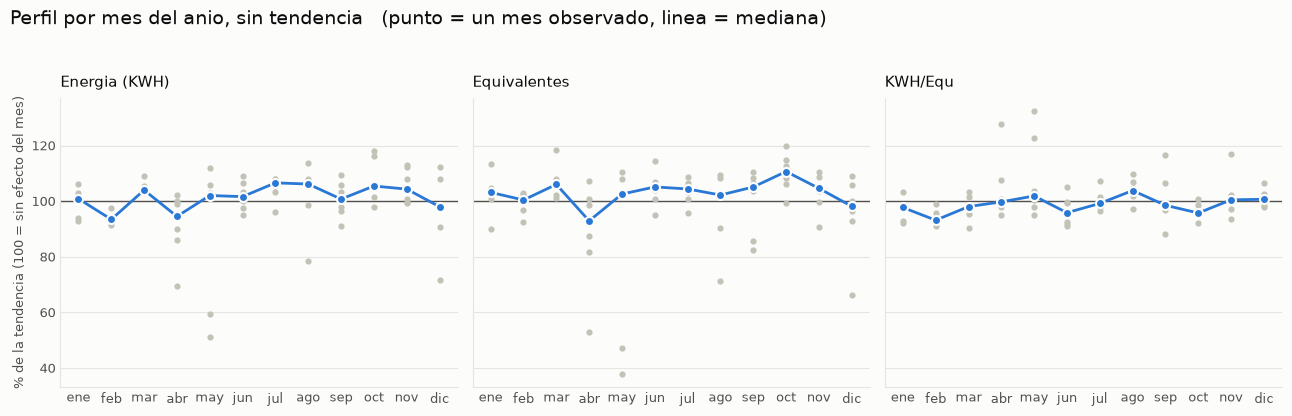

In [47]:
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
OBSERVACION = "#c3c2b7"  # gris de contexto: lo que no es el dato principal


def estilo_eje(ax: plt.Axes) -> None:
    """Superficie, grilla horizontal y ejes recesivos, como el resto del notebook."""
    ax.set_facecolor(SUPERFICIE)
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)


def rotulo_eje(valor: float, _posicion: float) -> str:
    """Miles con separador y sin decimales; valores chicos con 3 cifras significativas."""
    return f"{valor:,.0f}" if abs(valor) >= UMBRAL_MILES else f"{valor:,.3g}"


def perfil_por_grupo(
    ax: plt.Axes, valores: pd.Series, grupos: pd.Index, rotulos: list[str]
) -> None:
    """Dibuja cada observacion de un grupo y une las medianas de los grupos."""
    medianas = valores.groupby(grupos).median()
    posicion = {grupo: i for i, grupo in enumerate(medianas.index)}
    ax.scatter(
        [posicion[g] for g in grupos], valores, s=20, color=OBSERVACION, linewidths=0, zorder=2
    )
    ax.plot(
        range(len(medianas)),
        medianas.to_numpy(),
        color=LINEA,
        linewidth=2,
        marker="o",
        markersize=6.5,
        markeredgecolor=SUPERFICIE,
        markeredgewidth=1.5,
        zorder=3,
    )
    ax.set_xticks(range(len(medianas)), rotulos)
    estilo_eje(ax)


# Estacionalidad: se compara cada mes del anio contra los demas, ya sin la tendencia
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), facecolor=SUPERFICIE, sharey=True)
fig.suptitle(
    "Perfil por mes del anio, sin tendencia   (punto = un mes observado, linea = mediana)",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.98,
)
for ax, (nombre, s) in zip(axes, series_ts.items(), strict=True):
    relativo = sin_tendencia(s)
    perfil_por_grupo(ax, relativo, relativo.index.month, MESES)
    ax.axhline(100, color=TINTA_SUAVE, linewidth=1, zorder=1)
    ax.set_title(nombre, fontsize=10.5, color=TINTA, loc="left", pad=8)
axes[0].set_ylabel("% de la tendencia (100 = sin efecto del mes)", fontsize=9, color=TINTA_SUAVE)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [48]:
# Metricas explicitas del resumen de abajo
filas = []
for nombre, s in series_ts.items():
    for ventana, tramo in ventanas(s).items():
        for version, valores in [("bruta", tramo), ("sin tendencia", sin_tendencia(tramo))]:
            prueba = kruskal_por_grupo(valores, valores.index.month)
            filas.append({"serie": nombre, "ventana": ventana, "version": version, **prueba})

metricas_estacionalidad = pd.DataFrame(filas)
# Son 12 pruebas: Holm corrige el p-valor por haber mirado tantas veces
metricas_estacionalidad["p_holm"] = multipletests(
    metricas_estacionalidad["p_valor"], method="holm"
)[1]
metricas_estacionalidad["significativa"] = metricas_estacionalidad["p_holm"] < ALFA

# El mes mas alto y el mas bajo del perfil (mediana de cada mes, toda la historia)
filas = []
for nombre, s in series_ts.items():
    perfil = sin_tendencia(s).groupby(lambda fecha: fecha.month).median()
    filas.append(
        {
            "serie": nombre,
            "mes_pico": MESES[perfil.idxmax() - 1],
            "pico": perfil.max(),
            "mes_valle": MESES[perfil.idxmin() - 1],
            "valle": perfil.min(),
        }
    )
perfil_mensual = pd.DataFrame(filas).round(1)

print(
    f"pruebas: {len(metricas_estacionalidad)} | significativas tras Holm: "
    f"{int(metricas_estacionalidad['significativa'].sum())} | "
    f"p_valor minimo sin corregir: {metricas_estacionalidad['p_valor'].min():.4f}"
)
display(perfil_mensual)
metricas_estacionalidad.round(4)

pruebas: 12 | significativas tras Holm: 0 | p_valor minimo sin corregir: 0.0493


,serie,mes_pico,pico,mes_valle,valle
0,Energia (KWH),jul,106.6,feb,93.4
1,Equivalentes,oct,110.7,abr,92.9
2,KWH/Equ,ago,103.8,feb,93.2


,serie,ventana,version,grupos,n,H,p_valor,eta2,p_holm,significativa
0,Energia (KWH),historia,bruta,12,81,8.9490,0.6266,0.0000,1.0000,False
1,Energia (KWH),historia,sin tendencia,12,69,19.0618,0.0600,0.1414,0.6599,False
2,Energia (KWH),train,bruta,12,63,10.0544,0.5255,0.0000,1.0000,False
3,Energia (KWH),train,sin tendencia,12,51,15.6475,0.1547,0.1192,1.0000,False
4,Equivalentes,historia,bruta,12,81,6.0855,0.8676,0.0000,1.0000,False
5,Equivalentes,historia,sin tendencia,12,69,13.9130,0.2378,0.0511,1.0000,False
6,Equivalentes,train,bruta,12,63,10.0627,0.5248,0.0000,1.0000,False
7,Equivalentes,train,sin tendencia,12,51,15.4086,0.1645,0.1130,1.0000,False
8,KWH/Equ,historia,bruta,12,81,13.4626,0.2642,0.0357,1.0000,False
9,KWH/Equ,historia,sin tendencia,12,69,18.5814,0.0690,0.1330,0.6903,False


### Resumen: estacionalidad

- **Ninguna de las 12 pruebas es significativa tras corregir por comparaciones multiples**
  (Holm). El p-valor mas bajo sin corregir es 0.0493 (`KWH/Equ` bruta, en train); corregido
  sube a 0.5920.
- **Sin tendencia, dos series se acercan sin llegar**: energia (p 0.0600) y `KWH/Equ`
  (p 0.0690) con toda la historia, con tamanos de efecto de 0.1414 y 0.1330. En train las
  dos se alejan (0.1547 y 0.1073).
- **El perfil es suave**: la energia va de 93.4 % de la tendencia en febrero a 106.6 % en
  julio, y la produccion de 92.9 % en abril a 110.7 % en octubre. Es una pista, no una
  estacionalidad demostrada: con un minimo de 6 observaciones por mes (5 en train) la
  prueba tiene poca potencia.

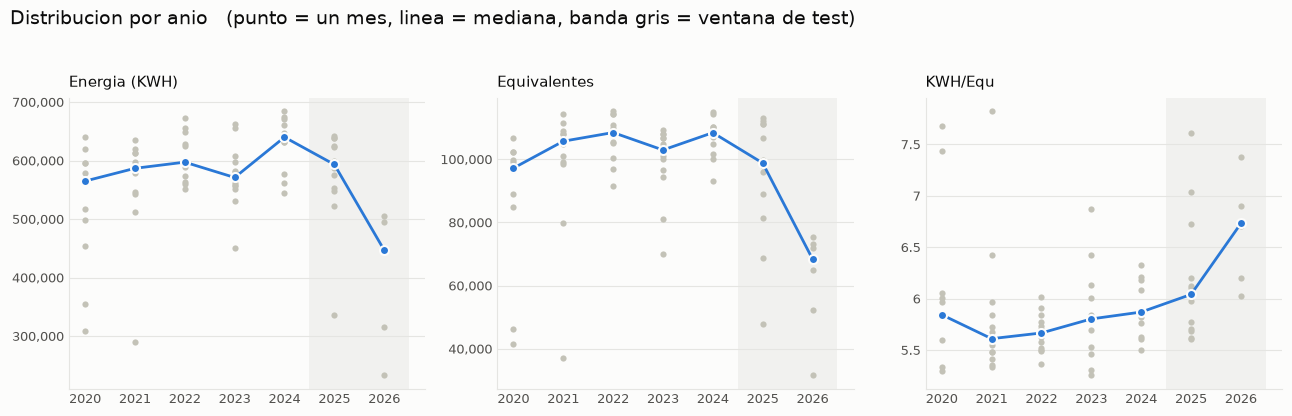

In [49]:
MIN_MESES_ANIO = 6  # un anio entra a la comparacion si tiene al menos medio anio de datos


def anios_comparables(s: pd.Series) -> pd.Series:
    """Deja solo los anios con suficientes meses para compararlos entre si."""
    meses_del_anio = s.groupby(s.index.year).transform("size")
    return s[meses_del_anio >= MIN_MESES_ANIO]


# Cambio sistematico: se compara cada anio contra los demas
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), facecolor=SUPERFICIE)
fig.suptitle(
    "Distribucion por anio   (punto = un mes, linea = mediana, banda gris = ventana de test)",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.98,
)
for ax, (nombre, s) in zip(axes, series_ts.items(), strict=True):
    tramo = anios_comparables(s)
    anios = sorted(set(tramo.index.year))
    perfil_por_grupo(ax, tramo, tramo.index.year, [str(a) for a in anios])
    # La ventana de test, sobre un eje de categorias: los anios desde el corte
    en_test = [i for i, a in enumerate(anios) if a >= CORTE_TS.year]
    ax.axvspan(en_test[0] - 0.5, en_test[-1] + 0.5, color=GRILLA, alpha=0.45, zorder=0, linewidth=0)
    ax.yaxis.set_major_formatter(rotulo_eje)
    ax.set_title(nombre, fontsize=10.5, color=TINTA, loc="left", pad=8)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [50]:
# Metricas explicitas del resumen de abajo
filas = []
for nombre, s in series_ts.items():
    for ventana, tramo in ventanas(s).items():
        comparables = anios_comparables(tramo)
        prueba = kruskal_por_grupo(comparables, comparables.index.year)
        # Mann-Kendall: correlacion de rangos (tau de Kendall) entre la serie y el tiempo.
        # Detecta una tendencia monotona; Kruskal-Wallis detecta cualquier diferencia.
        tau, p_tau = stats.kendalltau(np.arange(len(tramo)), tramo.to_numpy())
        direccion = "sin tendencia monotona"
        if p_tau < ALFA:
            direccion = "sube" if tau > 0 else "baja"
        filas.append(
            {
                "serie": nombre,
                "ventana": ventana,
                **prueba,
                "tau_mann_kendall": tau,
                "p_mann_kendall": p_tau,
                "direccion": direccion,
            }
        )

metricas_tendencia = pd.DataFrame(filas).rename(columns={"grupos": "anios"})
metricas_tendencia["p_holm"] = multipletests(metricas_tendencia["p_valor"], method="holm")[1]
metricas_tendencia["difiere_entre_anios"] = metricas_tendencia["p_holm"] < ALFA

# Donde esta el cambio: la mediana de cada anio
medianas_anuales = pd.DataFrame(
    {nombre: s.groupby(s.index.year).median() for nombre, s in series_ts.items()}
).round(2)
medianas_anuales["meses"] = planta.groupby(planta.index.year).size()

display(medianas_anuales)
metricas_tendencia.round(4)

,Energia (KWH),Equivalentes,KWH/Equ,meses
Mes_inicio,,,,
2019,573320.0,94701.48,5.63,3
2020,565023.0,97210.79,5.84,12
2021,586844.0,105730.83,5.61,12
2022,597385.0,108483.29,5.67,12
2023,571161.0,102955.55,5.80,12
2024,640085.0,108442.57,5.87,12
2025,593377.2,98826.26,6.04,12
2026,446961.5,68430.53,6.73,6


,serie,ventana,anios,n,H,p_valor,eta2,tau_mann_kendall,p_mann_kendall,direccion,p_holm,difiere_entre_anios
0,Energia (KWH),historia,7,78,25.3150,0.0003,0.2720,0.0358,0.6361,sin tendencia monotona,0.0015,True
1,Energia (KWH),train,5,60,12.8634,0.0120,0.1612,0.2842,0.0010,sube,0.0239,True
2,Equivalentes,historia,7,78,26.3684,0.0002,0.2869,0.0123,0.8704,sin tendencia monotona,0.0011,True
3,Equivalentes,train,5,60,15.9885,0.0030,0.2180,0.2873,0.0009,sube,0.0121,True
4,KWH/Equ,historia,7,78,17.5501,0.0075,0.1627,0.2494,0.0010,sube,0.0224,True
5,KWH/Equ,train,5,60,5.3262,0.2554,0.0241,0.0824,0.3396,sin tendencia monotona,0.2554,False


### Resumen: tendencia y cambio entre años

- **Las tres series cambian entre años en toda la historia** (Kruskal-Wallis con p de Holm
  de 0.0224 o menos, tamano de efecto de 0.1627 a 0.2869). No son series de nivel fijo.

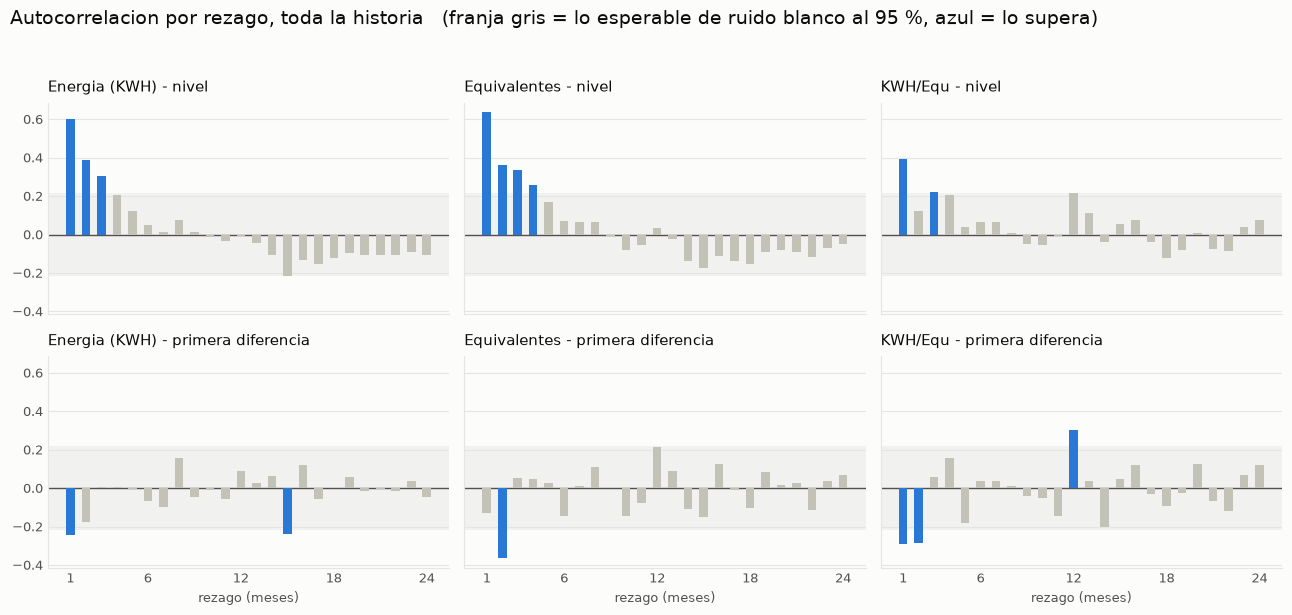

In [51]:
REZAGOS = 24  # dos ciclos anuales
TRANSFORMACIONES = {
    "nivel": lambda s: s,
    "primera diferencia": lambda s: s.diff().dropna(),
}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), facecolor=SUPERFICIE, sharex=True, sharey=True)
fig.suptitle(
    "Autocorrelacion por rezago, toda la historia"
    "   (franja gris = lo esperable de ruido blanco al 95 %, azul = lo supera)",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)
for fila_ejes, (transformacion, aplicar) in zip(axes, TRANSFORMACIONES.items(), strict=True):
    for ax, (nombre, s) in zip(fila_ejes, series_ts.items(), strict=True):
        valores = aplicar(s)
        r = acf(valores, nlags=REZAGOS, fft=False)[1:]  # sin el rezago 0, que siempre es 1
        banda = Z_CRITICO / np.sqrt(len(valores))
        ax.axhspan(-banda, banda, color=GRILLA, alpha=0.45, zorder=0, linewidth=0)
        ax.bar(
            range(1, REZAGOS + 1),
            r,
            width=0.55,
            color=[LINEA if abs(v) > banda else OBSERVACION for v in r],
            zorder=3,
        )
        ax.axhline(0, color=TINTA_SUAVE, linewidth=1, zorder=2)
        ax.set_title(f"{nombre} - {transformacion}", fontsize=10.5, color=TINTA, loc="left", pad=8)
        ax.set_xticks([1, 6, 12, 18, 24])
        estilo_eje(ax)
for ax in axes[-1]:
    ax.set_xlabel("rezago (meses)", fontsize=9, color=TINTA_SUAVE)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [52]:
# Metricas explicitas del resumen de abajo
filas = []
for nombre, s in series_ts.items():
    for ventana, tramo in ventanas(s).items():
        for transformacion, aplicar in TRANSFORMACIONES.items():
            valores = aplicar(tramo)
            r = acf(valores, nlags=REZAGOS, fft=False)
            banda = Z_CRITICO / np.sqrt(len(valores))
            fuera = [k for k in range(1, REZAGOS + 1) if abs(r[k]) > banda]
            # Ljung-Box: H0 = no hay autocorrelacion en los primeros 12 rezagos
            ljung_box = acorr_ljungbox(valores, lags=[PERIODO])
            filas.append(
                {
                    "serie": nombre,
                    "ventana": ventana,
                    "transformacion": transformacion,
                    "n": len(valores),
                    "banda": banda,
                    "r1": r[1],
                    "r12": r[PERIODO],
                    "rezagos_fuera_de_banda": ", ".join(map(str, fuera)) or "ninguno",
                    "ljung_box_p": ljung_box["lb_pvalue"].iloc[0],
                    "ruido_blanco": ljung_box["lb_pvalue"].iloc[0] >= ALFA,
                }
            )

metricas_autocorrelacion = pd.DataFrame(filas)
metricas_autocorrelacion.round(3)

,serie,ventana,transformacion,n,banda,r1,r12,rezagos_fuera_de_banda,ljung_box_p,ruido_blanco
0,Energia (KWH),historia,nivel,81,0.218,0.599,-0.006,"1, 2, 3",0.000,False
1,Energia (KWH),historia,primera diferencia,80,0.219,-0.243,0.087,"1, 15",0.424,True
2,Energia (KWH),train,nivel,63,0.247,0.483,0.115,"1, 2",0.022,False
3,Energia (KWH),train,primera diferencia,62,0.249,-0.286,0.127,"1, 15",0.321,True
4,Equivalentes,historia,nivel,81,0.218,0.636,0.033,"1, 2, 3, 4",0.000,False
5,Equivalentes,historia,primera diferencia,80,0.219,-0.132,0.213,2,0.027,False
6,Equivalentes,train,nivel,63,0.247,0.482,0.229,1,0.038,False
7,Equivalentes,train,primera diferencia,62,0.249,-0.140,0.287,"2, 12",0.053,True
8,KWH/Equ,historia,nivel,81,0.218,0.394,0.216,"1, 3",0.005,False
9,KWH/Equ,historia,primera diferencia,80,0.219,-0.288,0.301,"1, 2, 12",0.002,False


### Resumen: autocorrelacion

En las variables en su nivel original se ve una fuerte autocorrelación ($r_1 > 0.39$) que se hace notar de manera grafica al ver el lento descenso de las barras de los primeros periodos, esto indica que esta aucorrelacion tiende a jalar información de meses anteriores por un tiempo considerable.

Sin embargo eso se soliciona con la pri,era diferencia, la cual elimina la autocorrelación en su mayoria y colapasa la estructura temporal a una sola foto del periodo especifico, esto sin arrastrar info previa, de tal manera que se ve solo la señal de ese periodo (en su mayoria, puues equivalentes con toda la historia, KWH/Equ en train y historico son la excepcion).

In [53]:
# Metricas explicitas del resumen de abajo
# ADF y KPSS tienen hipotesis nulas opuestas, por eso se leen juntas:
#   ADF  -> H0: la serie tiene raiz unitaria (no es estacionaria)
#   KPSS -> H0: la serie es estacionaria alrededor de un nivel constante
def diagnostico(p_adf: float, p_kpss: float) -> str:
    """Lectura conjunta de ADF y KPSS al nivel ALFA."""
    sin_raiz_unitaria = p_adf < ALFA
    nivel_constante = p_kpss >= ALFA
    if sin_raiz_unitaria and nivel_constante:
        return "estacionaria"
    if sin_raiz_unitaria:
        return "sin raiz unitaria, pero el nivel cambia"
    if nivel_constante:
        return "no concluyente"
    return "no estacionaria"


filas = []
for nombre, s in series_ts.items():
    for ventana, tramo in ventanas(s).items():
        for transformacion, aplicar in TRANSFORMACIONES.items():
            valores = aplicar(tramo)
            prueba_adf = adfuller(valores, autolag="AIC", result_object=True)
            # KPSS solo tabula p-valores entre 0.01 y 0.10 y avisa cuando el estadistico
            # cae fuera: el aviso se silencia y el limite se documenta en el resumen.
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", InterpolationWarning)
                prueba_kpss = kpss(valores, regression="c", nlags="auto", result_object=True)
            filas.append(
                {
                    "serie": nombre,
                    "ventana": ventana,
                    "transformacion": transformacion,
                    "adf": prueba_adf.statistic,
                    "adf_p": prueba_adf.pvalue,
                    "kpss": prueba_kpss.statistic,
                    "kpss_p": prueba_kpss.pvalue,
                    "diagnostico": diagnostico(prueba_adf.pvalue, prueba_kpss.pvalue),
                }
            )

metricas_estacionariedad = pd.DataFrame(filas)
metricas_estacionariedad.round(3)

,serie,ventana,transformacion,adf,adf_p,kpss,kpss_p,diagnostico
0,Energia (KWH),historia,nivel,-4.382,0.000,0.183,0.100,estacionaria
1,Energia (KWH),historia,primera diferencia,-8.777,0.000,0.122,0.100,estacionaria
2,Energia (KWH),train,nivel,-4.529,0.000,0.592,0.023,"sin raiz unitaria, pero el nivel cambia"
3,Energia (KWH),train,primera diferencia,-7.153,0.000,0.086,0.100,estacionaria
4,Equivalentes,historia,nivel,-2.422,0.136,0.232,0.100,no concluyente
5,Equivalentes,historia,primera diferencia,-9.846,0.000,0.500,0.042,"sin raiz unitaria, pero el nivel cambia"
6,Equivalentes,train,nivel,-4.542,0.000,0.430,0.064,estacionaria
7,Equivalentes,train,primera diferencia,-5.814,0.000,0.243,0.100,estacionaria
8,KWH/Equ,historia,nivel,0.391,0.981,0.458,0.052,no concluyente
9,KWH/Equ,historia,primera diferencia,-5.464,0.000,0.183,0.100,estacionaria


### Resumen: estacionariedad

- **En train ninguna serie es un paseo aleatorio.** ADF descarta la raiz unitaria en las
  tres (p 0.000 a tres decimales).
- **Produccion y `KWH/Equ` son estacionarias en train; la energia no del todo.** KPSS le
  rechaza el nivel constante (p 0.023): es la subida ya vista.
- **Con 2025-2026 el diagnostico cambia.** `KWH/Equ` deja de rechazar la raiz unitaria (ADF
  p 0.981) y la produccion tampoco la rechaza (p 0.136): el salto del final hace que la
  serie ya no parezca estacionaria.
- **La primera diferencia es estacionaria en 5 de los 6 casos**; la excepcion es la
  produccion con toda la historia (KPSS p 0.042).
- KPSS solo tabula p-valores hasta 0.10: un 0.100 en la tabla significa "0.10 o mas".

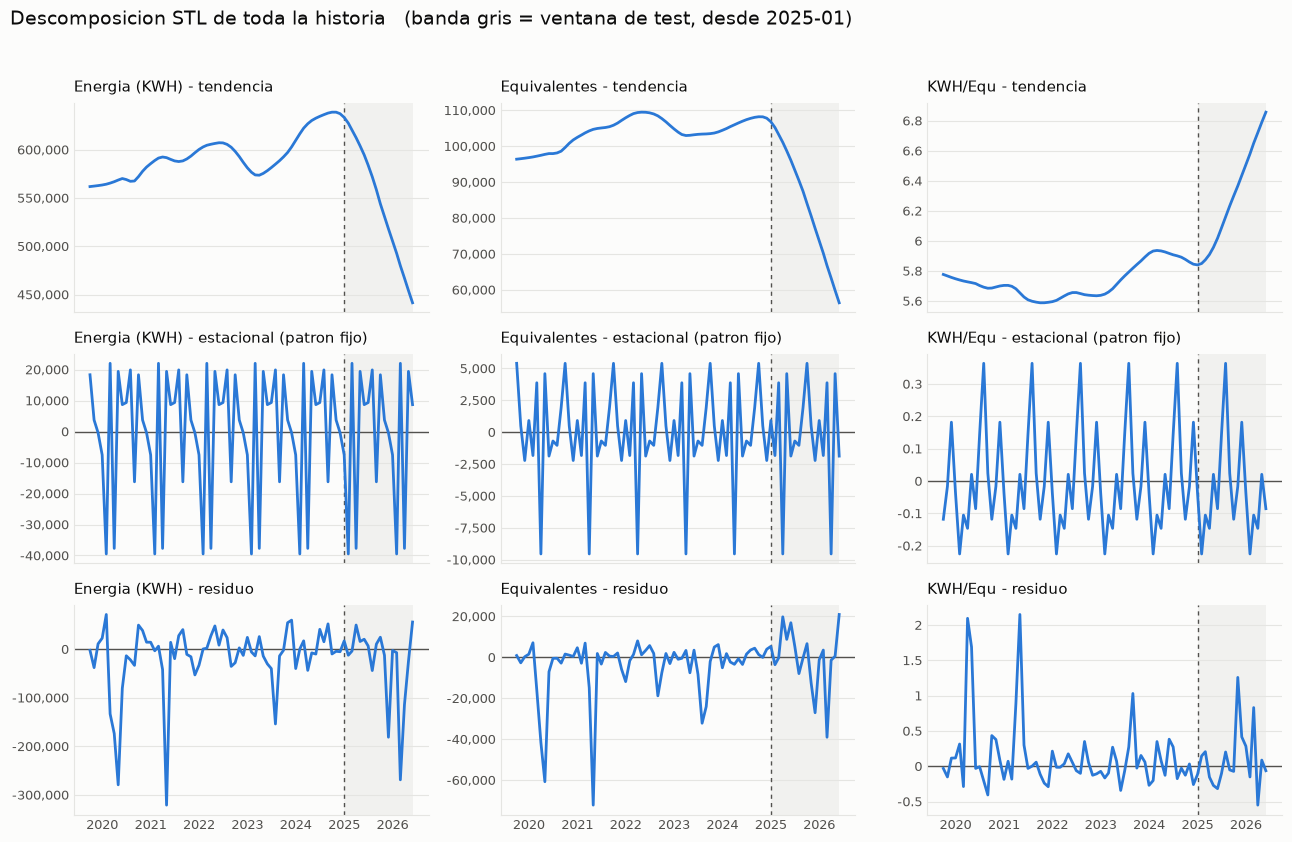

In [54]:
# Descomposicion STL: tendencia + estacional + residuo.
# Con 7 ciclos no se puede estimar un patron estacional que evolucione. El suavizador por
# defecto deja que el efecto de cada mes cambie de anio en anio, y asi absorbe como
# "estacionalidad" los meses anomalos de 2020 y 2021. Por eso se impone un
# patron fijo (grado 0 y una ventana mucho mas larga que la serie: la media de cada mes
# del anio), y el ajuste robusto manda esos meses al residuo, que es donde corresponden.
def descomponer(s: pd.Series) -> DecomposeResult:
    """STL robusta con patron estacional fijo."""
    ventana_fija = 10 * len(s) + 1  # tiene que ser impar
    return STL(s, period=PERIODO, seasonal=ventana_fija, seasonal_deg=0, robust=True).fit()


ajustes_stl = {
    (nombre, ventana): descomponer(tramo)
    for nombre, s in series_ts.items()
    for ventana, tramo in ventanas(s).items()
}

fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), facecolor=SUPERFICIE, sharex=True)
fig.suptitle(
    "Descomposicion STL de toda la historia   (banda gris = ventana de test, desde 2025-01)",
    fontsize=14,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)
for columna, nombre in enumerate(series_ts):
    ajuste = ajustes_stl[nombre, "historia"]
    componentes = {
        "tendencia": ajuste.trend,
        "estacional (patron fijo)": ajuste.seasonal,
        "residuo": ajuste.resid,
    }
    for fila_eje, (componente, valores) in enumerate(componentes.items()):
        ax = axes[fila_eje, columna]
        ax.plot(valores.index, valores, color=LINEA, linewidth=2, zorder=3)
        if componente != "tendencia":
            ax.axhline(0, color=TINTA_SUAVE, linewidth=1, zorder=2)
        marcar_test(ax, valores.index[0], valores.index[-1])
        estilo_eje(ax)
        ax.yaxis.set_major_formatter(rotulo_eje)
        ax.set_title(f"{nombre} - {componente}", fontsize=10.5, color=TINTA, loc="left", pad=8)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [55]:
# Metricas explicitas del resumen de abajo
# Umbral de fuerza estacional a partir del cual se suele diferenciar por estacion
# (Wang, Smith y Hyndman, 2006; es el que usa el paquete feasts)
UMBRAL_ESTACIONAL = 0.64
UMBRAL_ATIPICO = 3  # desviaciones robustas a partir de las que un residuo es atipico
ESCALA_MAD = 1.4826  # vuelve la desviacion absoluta mediana comparable con una desviacion estandar


def fuerza(componente: pd.Series, residuo: pd.Series) -> float:
    """Fuerza de un componente STL: 1 - Var(residuo) / Var(componente + residuo)."""
    return max(0.0, 1 - residuo.var() / (componente + residuo).var())


def rango_intercuartil(x: pd.Series) -> float:
    """Distancia entre los cuartiles 1 y 3: una dispersion que ignora las colas."""
    return x.quantile(0.75) - x.quantile(0.25)


def fuerza_robusta(componente: pd.Series, residuo: pd.Series) -> float:
    """La misma fuerza, con el rango intercuartil en lugar de la varianza."""
    razon = rango_intercuartil(residuo) / rango_intercuartil(componente + residuo)
    return max(0.0, 1 - razon**2)


filas = []
atipicos_historia = {}
for (nombre, ventana), ajuste in ajustes_stl.items():
    serie_ts = series_ts[nombre]
    # El patron fijo, como porcentaje de la mediana de la serie
    patron = 100 * ajuste.seasonal.groupby(lambda fecha: fecha.month).mean() / serie_ts.median()
    desvio = (ajuste.resid - ajuste.resid.median()).abs()
    atipico = desvio > UMBRAL_ATIPICO * ESCALA_MAD * desvio.median()
    if ventana == "historia":
        atipicos_historia[nombre] = ", ".join(
            f"{fecha:%Y-%m}" for fecha in ajuste.resid.index[atipico]
        )
    filas.append(
        {
            "serie": nombre,
            "ventana": ventana,
            "fuerza_tendencia": fuerza(ajuste.trend, ajuste.resid),
            "fuerza_tendencia_robusta": fuerza_robusta(ajuste.trend, ajuste.resid),
            "fuerza_estacional": fuerza(ajuste.seasonal, ajuste.resid),
            "fuerza_estacional_robusta": fuerza_robusta(ajuste.seasonal, ajuste.resid),
            "mes_pico": MESES[patron.idxmax() - 1],
            "pico_pct": patron.max(),
            "mes_valle": MESES[patron.idxmin() - 1],
            "valle_pct": patron.min(),
            "residuos_atipicos": int(atipico.sum()),
        }
    )

metricas_stl = pd.DataFrame(filas)
metricas_stl["estacionalidad_marcada"] = metricas_stl["fuerza_estacional"] >= UMBRAL_ESTACIONAL

# Los meses que el ajuste robusto deja en el residuo (toda la historia)
for nombre, meses_atipicos in atipicos_historia.items():
    print(f"{nombre}: {meses_atipicos}")
metricas_stl.round(2)

Energia (KWH): 2020-03, 2020-04, 2020-05, 2021-05, 2023-08, 2025-12, 2026-03, 2026-04
Equivalentes: 2020-03, 2020-04, 2020-05, 2021-04, 2021-05, 2022-09, 2023-08, 2023-09, 2025-04, 2025-06, 2025-12, 2026-03, 2026-06
KWH/Equ: 2020-04, 2020-05, 2021-04, 2021-05, 2023-09, 2025-11, 2026-03


,serie,ventana,fuerza_tendencia,fuerza_tendencia_robusta,fuerza_estacional,fuerza_estacional_robusta,mes_pico,pico_pct,mes_valle,valle_pct,residuos_atipicos,estacionalidad_marcada
0,Energia (KWH),historia,0.38,0.61,0.01,0.47,mar,3.79,feb,-6.80,8,False
1,Energia (KWH),train,0.20,0.44,0.00,0.43,ago,5.45,abr,-7.99,5,False
2,Equivalentes,historia,0.42,0.75,0.00,0.47,oct,5.31,abr,-9.40,13,False
3,Equivalentes,train,0.16,0.65,0.04,0.54,mar,4.76,abr,-6.82,8,False
4,KWH/Equ,historia,0.28,0.51,0.06,0.30,ago,6.24,feb,-3.87,7,False
5,KWH/Equ,train,0.06,0.20,0.13,0.49,ago,5.21,feb,-4.29,5,False


### Resumen: descomposicion STL

Se ve una fuerte tendencia a la baja en el consumo y prod, junto a una subida en el gasto energetico por equivalente, lo cual respalda los primeros hallazgos del cuaderno, ademas se observa como la descompocición estacional da por resultado un movimiento ruidoso que parece car saltos o tener picos en la mitad del año.

Esto ultimo se ve respaldado por los picos hallados en la tabla resumen de esta sección. 

> nota: en esta oportunidad la fuerza estacional es particularmente baja, lo cual respalda el indicio de que este archivo con split temporal de solo unos cuantos cortes por mes no muestra la estacionalidad de archivos mas granulares. 

In [56]:
# Todo el diagnostico en una tabla: una fila por serie y ventana
claves = ["serie", "ventana"]
kw_mes = metricas_estacionalidad.query("version == 'sin tendencia'")
en_nivel = "transformacion == 'nivel'"
en_diferencia = "transformacion == 'primera diferencia'"

diagnostico_ts = (
    kw_mes[[*claves, "p_holm", "significativa"]]
    .rename(columns={"p_holm": "kw_mes_p_holm", "significativa": "estacionalidad"})
    .merge(
        metricas_tendencia[[*claves, "difiere_entre_anios", "direccion"]].rename(
            columns={"direccion": "tendencia_monotona"}
        ),
        on=claves,
    )
    .merge(metricas_autocorrelacion.query(en_nivel)[[*claves, "r1", "r12"]], on=claves)
    .merge(
        metricas_autocorrelacion.query(en_diferencia)[[*claves, "ruido_blanco"]].rename(
            columns={"ruido_blanco": "diferencia_es_ruido_blanco"}
        ),
        on=claves,
    )
    .merge(
        metricas_estacionariedad.query(en_nivel)[[*claves, "diagnostico"]].rename(
            columns={"diagnostico": "estacionariedad_en_nivel"}
        ),
        on=claves,
    )
    .merge(metricas_stl[[*claves, "fuerza_estacional", "fuerza_estacional_robusta"]], on=claves)
)
diagnostico_ts.round(3)

,serie,ventana,kw_mes_p_holm,estacionalidad,difiere_entre_anios,tendencia_monotona,r1,r12,diferencia_es_ruido_blanco,estacionariedad_en_nivel,fuerza_estacional,fuerza_estacional_robusta
0,Energia (KWH),historia,0.660,False,True,sin tendencia monotona,0.599,-0.006,True,estacionaria,0.013,0.470
1,Energia (KWH),train,1.000,False,True,sube,0.483,0.115,True,"sin raiz unitaria, pero el nivel cambia",0.000,0.426
2,Equivalentes,historia,1.000,False,True,sin tendencia monotona,0.636,0.033,False,no concluyente,0.005,0.465
3,Equivalentes,train,1.000,False,True,sube,0.482,0.229,True,estacionaria,0.040,0.537
4,KWH/Equ,historia,0.690,False,True,sube,0.394,0.216,False,no concluyente,0.063,0.298
5,KWH/Equ,train,0.966,False,False,sin tendencia monotona,0.296,0.351,False,estacionaria,0.128,0.487


### Resumen general: que dicen las series

- **No hay estacionalidad demostrable.** Kruskal-Wallis por mes no es significativo en
  ninguna serie ni ventana (p de Holm de 0.660 a 1.000) y la fuerza estacional clasica no
  supera 0.128.
- **El unico indicio de ciclo anual esta en `KWH/Equ`**: su rezago 12 llega a 0.351 en
  train. Vale la pena vigilarlo, pero con tan pocos años no alcanza para afirmarlo.
- **La memoria es de pocos meses.** El rezago 1 va de 0.296 a 0.636.
- **Train y toda la historia no cuentan lo mismo.** En train `KWH/Equ` es estacionaria y no
  difiere entre años; al sumar 2025-2026 deja de serlo. Un modelo ajustado en train no
  tiene de donde aprender ese salto.